# Predicting Elevated S&P 500 Volatility, and Testing It on FX

## Summary of findings
- **S&P 500:** a five-feature logistic regression beat a 20-day-volatility rule in all four walk-forward folds (mean AUC 0.815 vs 0.773) and on the later test period (0.711 vs 0.611; 95% interval for the difference +0.04 to +0.17). Gradient boosting and GARCH added nothing reliable on top of it.
- **FX (GBP/USD, EUR/GBP, USD/JPY):** no model clearly beat the 20-day rule, so the equity result did not carry over.
- Probabilities overstate risk in the test period, so the model is useful for ranking, not as literal probabilities. See Sections 21 and 22 for limitations and details.


## Research question
Can historical returns and rolling volatility help identify elevated S&P 500 volatility over the next five trading days?

This project constructs a forward-looking realised-volatility target, explores historical market behaviour, and compares logistic regression, random forest, gradient boosting and GARCH(1,1). The analysis develops from an initial chronological train–test experiment into a train–validation–test design and then expanding-window validation.

The notebook is an exploratory research record. Its later evaluation period was examined early in development, so the final results are a chronological evaluation on previously inspected data, rather than an independent confirmation on an untouched holdout. The narrative preserves that experimental sequence.

All numerical results below describe the saved notebook outputs. Daily returns are expressed in percent; volatility is the standard deviation of those daily percentage returns and is not annualised. Predictions use information available through the close of date $t$ to describe returns on dates $t+1$ through $t+5$.

## Environment
The next cells install the initial dependencies and import the data, numerical and plotting libraries. Additional packages are installed later when first needed. Package installation cells do not pin versions, so a future run may differ from the saved run.

In [1]:
%pip install yfinance pandas numpy matplotlib scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

## 1. Collecting and inspecting the market data

Daily S&P 500 index data are requested from Yahoo Finance through `yfinance`, using ticker `^GSPC`, a start date of 1 January 2010 and an exclusive end date of 1 October 2026. The download requests automatically adjusted prices.

The next cells inspect the first rows, dimensions, data types and missing values, then plot closing index levels. The fields are Open, High, Low and Close index levels, together with provider-reported Volume. Volume is inspected but is not used as a predictor in the models implemented here.

In [3]:
# download our data
sp500 = yf.download(
    "^GSPC",
    start="2010-01-01",
    end="2026-10-01",
    auto_adjust=True,
    progress=False
)

In [4]:
# inspect our data
sp500.head()

Price,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,
2010-01-04,1132.989990,1133.869995,1116.560059,1116.560059,3991400000
2010-01-05,1136.520020,1136.630005,1129.660034,1132.660034,2491020000
2010-01-06,1137.140015,1139.189941,1133.949951,1135.709961,4972660000
2010-01-07,1141.689941,1142.459961,1131.319946,1136.270020,5270680000
2010-01-08,1144.979980,1145.390015,1136.219971,1140.520020,4389590000


In [5]:
sp500.shape

(4211, 5)

In [6]:
sp500.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 4211 entries, 2010-01-04 to 2026-09-30
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   (Close, ^GSPC)   4211 non-null   float64
 1   (High, ^GSPC)    4211 non-null   float64
 2   (Low, ^GSPC)     4211 non-null   float64
 3   (Open, ^GSPC)    4211 non-null   float64
 4   (Volume, ^GSPC)  4211 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 197.4 KB


In [7]:
sp500.isnull().sum()

Price   Ticker
Close   ^GSPC     0
High    ^GSPC     0
Low     ^GSPC     0
Open    ^GSPC     0
Volume  ^GSPC     0
dtype: int64

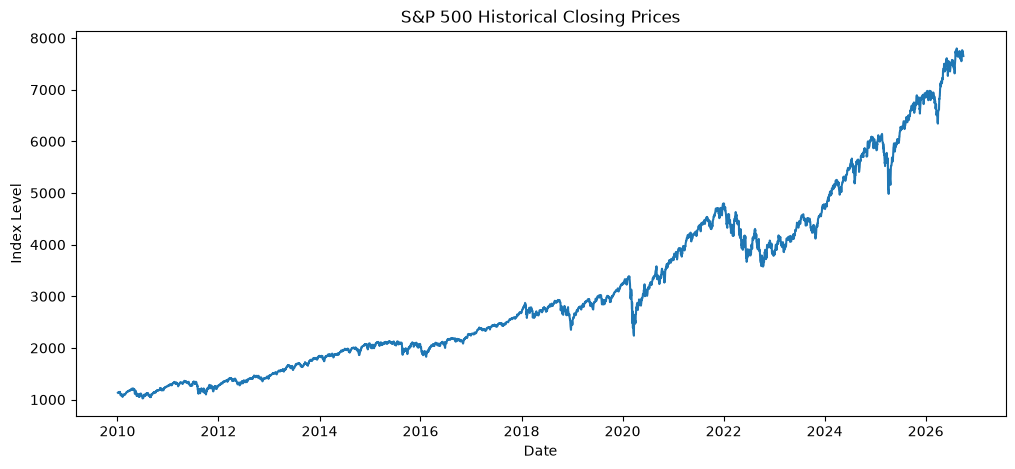

In [8]:
plt.figure(figsize=(12, 5))

plt.plot(sp500.index, sp500["Close"])

plt.title("S&P 500 Historical Closing Prices")
plt.xlabel("Date")
plt.ylabel("Index Level")

plt.show()


### Data inspection and price history

The saved download contains **4,211 daily observations**, from **4 January 2010 to 30 September 2026**, with no missing values in its five downloaded columns. This check concerns missing entries in the returned table; it does not independently verify the provider's historical records or completeness of the trading calendar.

The price chart shows a long-term increase interrupted by substantial drawdowns and recoveries, including a pronounced decline around early 2020. Index-point movements are difficult to compare across different price levels, motivating the use of percentage returns. The plot alone does not establish the causes of individual movements.

## 2. Calculating daily percentage returns

The next cell flattens the downloaded column index. Daily simple returns are then calculated as

$$r_t=100\left(\frac{P_t}{P_{t-1}}-1\right),$$

where $P_t$ is the closing index level. The first return is missing because no previous close is available within the downloaded sample.

In [9]:
sp500.columns = sp500.columns.get_level_values(0)
sp500.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2010-01-04,1132.989990,1133.869995,1116.560059,1116.560059,3991400000
2010-01-05,1136.520020,1136.630005,1129.660034,1132.660034,2491020000
2010-01-06,1137.140015,1139.189941,1133.949951,1135.709961,4972660000
2010-01-07,1141.689941,1142.459961,1131.319946,1136.270020,5270680000
2010-01-08,1144.979980,1145.390015,1136.219971,1140.520020,4389590000


In [10]:
sp500["Daily_Return"] = sp500["Close"].pct_change() * 100
sp500[["Close", "Daily_Return"]].head()

Price,Close,Daily_Return
Date,,
2010-01-04,1132.989990,NaN
2010-01-05,1136.520020,0.311568
2010-01-06,1137.140015,0.054552
2010-01-07,1141.689941,0.400120
2010-01-08,1144.979980,0.288173


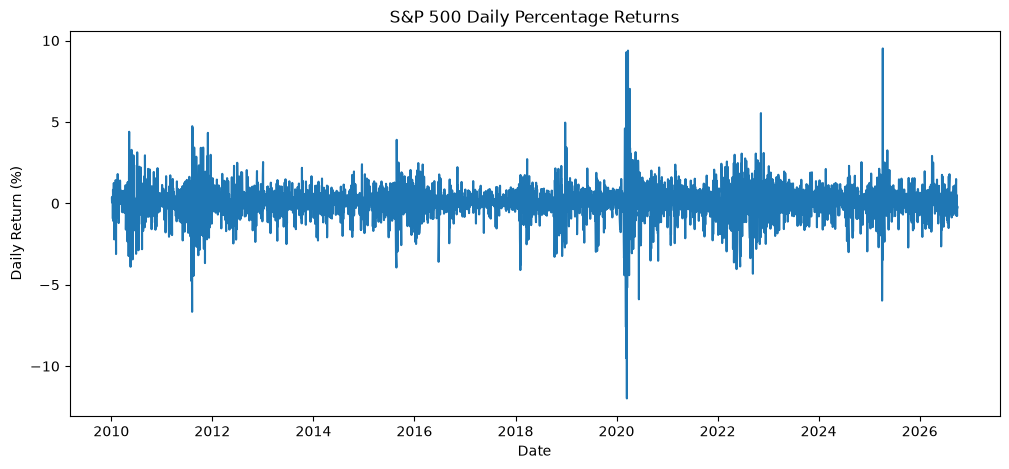

In [11]:
plt.figure(figsize=(12, 5))
plt.plot(sp500.index, sp500["Daily_Return"])
plt.title("S&P 500 Daily Percentage Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")

plt.show()


In [12]:
sp500["Daily_Return"].describe()

count    4210.000000
mean        0.051241
std         1.081255
min       -11.984055
25%        -0.381186
50%         0.068743
75%         0.570120
max         9.515388
Name: Daily_Return, dtype: float64

### Return behaviour

There are **4,210 non-missing returns**. The saved summary reports a daily mean of **0.0512%**, standard deviation of **1.0813 percentage points**, minimum of **−11.9841%** and maximum of **9.5154%**.

The return plot shows large movements concentrated in particular periods, consistent with volatility clustering. This visual pattern motivates predictive features; it is not a formal statistical test of persistence.

## 3. Measuring historical rolling volatility

Historical volatility is measured using the sample standard deviation of daily percentage returns over trailing windows of 5, 20 and 60 trading days. Each window includes the current date's return. Pandas' default sample-standard-deviation convention uses a denominator of $n-1$.

A value of 1.0 corresponds to a daily-return standard deviation of one percentage point within the window. These measures are neither annualised volatility nor cumulative returns over the window.

In [13]:
sp500["Volatility_20d"] = sp500["Daily_Return"].rolling(window=20).std()
sp500[["Daily_Return", "Volatility_20d"]].tail()

Price,Daily_Return,Volatility_20d
Date,,
2026-09-24,-0.024655,0.691111
2026-09-25,0.509860,0.681433
2026-09-28,-0.771239,0.701601
2026-09-29,-0.167239,0.698650
2026-09-30,-0.251600,0.681638


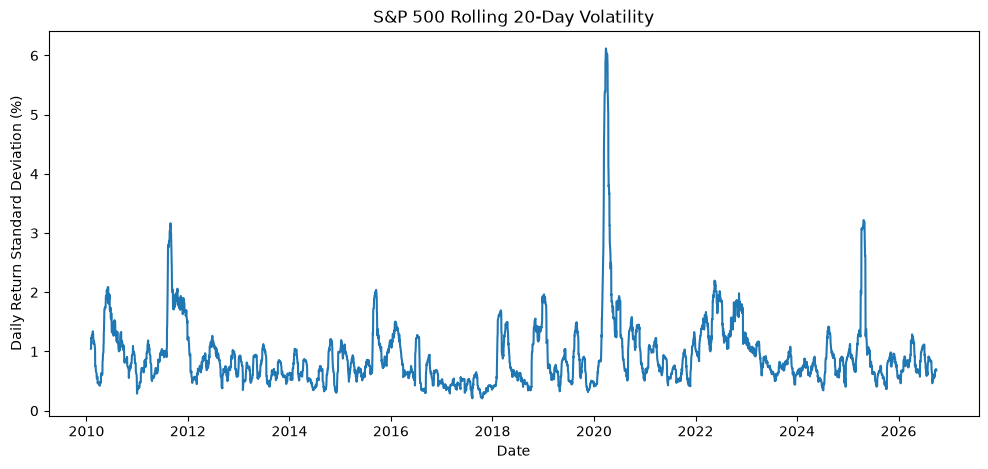

In [14]:
plt.figure(figsize=(12, 5))
plt.plot(sp500.index, sp500["Volatility_20d"])
plt.title("S&P 500 Rolling 20-Day Volatility")
plt.xlabel("Date")
plt.ylabel("Daily Return Standard Deviation (%)")
plt.show()

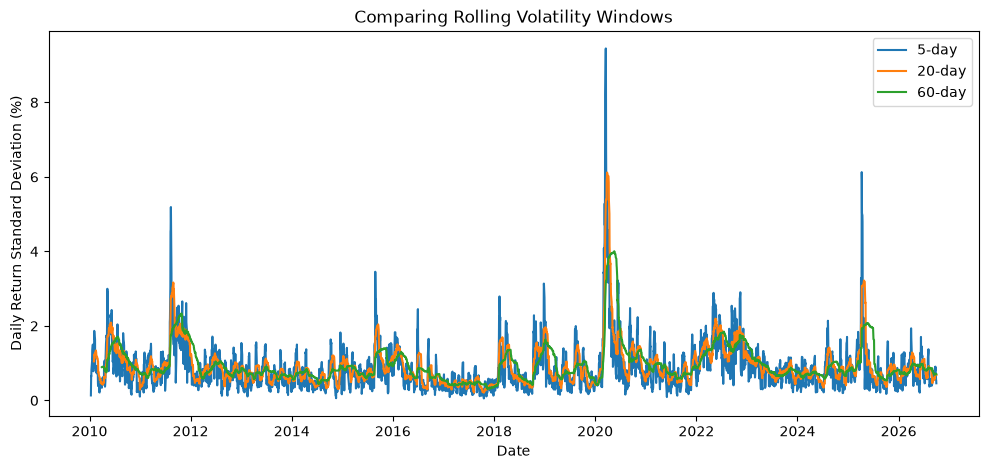

In [15]:
sp500["Volatility_5d"] = sp500["Daily_Return"].rolling(window=5).std()
sp500["Volatility_60d"] = sp500["Daily_Return"].rolling(window=60).std()

plt.figure(figsize=(12, 5))
plt.plot(sp500.index, sp500["Volatility_5d"], label="5-day")
plt.plot(sp500.index, sp500["Volatility_20d"], label="20-day")
plt.plot(sp500.index, sp500["Volatility_60d"], label="60-day")
plt.title("Comparing Rolling Volatility Windows")
plt.xlabel("Date")
plt.ylabel("Daily Return Standard Deviation (%)")
plt.legend()
plt.show()

### Comparing the volatility windows

The five-day measure responds quickly to new observations but is relatively noisy. The 60-day measure is smoother and responds more slowly, while the 20-day measure provides an intermediate horizon. Early rows are missing until a full window of valid returns is available.

The saved charts show a particularly large spike around early 2020, with 20-day volatility exceeding 6 percentage points. Shorter and longer windows respond differently to the same disturbance. These patterns motivate a later feature comparing five-day with 60-day volatility.

## 4. Constructing the forward-looking target

For each date $t$, the continuous target is the sample standard deviation of the **next five trading-day returns**:

$$v_t^{\mathrm{future}}=\operatorname{sd}(r_{t+1},r_{t+2},r_{t+3},r_{t+4},r_{t+5}).$$

Today's return is excluded from this target. The final five dates have no complete future window and receive missing targets. This quantity measures dispersion of daily returns over the coming week, rather than the standard deviation of a single five-day cumulative return.

The next cells construct the target, inspect its alignment and compare the first target with a direct calculation.

In [16]:
future_volatility = []

returns = sp500["Daily_Return"]

for i in range(len(sp500)):
    next_5_days = returns.iloc[i+1:i+6]

    if len(next_5_days) == 5:
        future_volatility.append(next_5_days.std())
    else:
        future_volatility.append(np.nan)

sp500["Future_Volatility_5d"] = future_volatility


In [17]:
sp500[[
    "Daily_Return",
    "Volatility_5d",
    "Future_Volatility_5d"
]].head(10)

Price,Daily_Return,Volatility_5d,Future_Volatility_5d
Date,,,
2010-01-04,NaN,NaN,0.133763
2010-01-05,0.311568,NaN,0.537728
2010-01-06,0.054552,NaN,0.658062
2010-01-07,0.400120,NaN,0.646860
2010-01-08,0.288173,NaN,0.823912
2010-01-11,0.174676,0.133763,1.042519
2010-01-12,-0.938117,0.537728,1.072652
2010-01-13,0.832593,0.658062,1.246049
2010-01-14,0.242643,0.646860,1.355252


In [18]:
# check match
print(sp500["Daily_Return"].iloc[1:6].std())

print(sp500["Future_Volatility_5d"].iloc[0])


0.13376285070849103
0.13376285070849103


### Target-alignment check

The direct calculation and the stored first target both equal **0.1337628507**, confirming alignment for that example. The preview also shows that future volatility can be above or below trailing volatility; no general direction follows from a few rows.

Adjacent targets share four of their five underlying returns. Consequently, daily labels and forecast errors are dependent, and counts of high-volatility observations should not be interpreted as counts of independent market episodes.

## 5. Preparing the initial classification dataset

The first feature set contains trailing five-day, 20-day and 60-day volatility. Rows missing any feature or the continuous future target are removed. The remaining **4,146 observations** are split chronologically: the first 80% form the initial training portion and the last 20% form the initial test portion.

Five observations are then removed from the end of the training portion to separate its forward target windows from the test period. High volatility is defined as future five-day volatility **strictly greater than the 75th percentile of the retained training targets**. The same training-derived cutoff is applied to test targets.

This volatility cutoff defines the true class. It is distinct from the probability cutoff later used to turn a model score into an alert.

In [19]:
features = [
    "Volatility_5d",
    "Volatility_20d",
    "Volatility_60d"
]

In [20]:
model_df = sp500[
    features + ["Future_Volatility_5d"]
].copy()

model_df = model_df.dropna()

model_df.head()

Price,Volatility_5d,Volatility_20d,Volatility_60d,Future_Volatility_5d
Date,,,,
2010-03-31,0.339187,0.473204,0.894584,0.557648
2010-04-01,0.435976,0.486342,0.898372,0.543674
2010-04-05,0.493708,0.425198,0.903284,0.460715
2010-04-06,0.482966,0.421966,0.902370,0.462024
2010-04-07,0.619463,0.459068,0.905897,0.424303


In [21]:
# split training + test data 80/20

split_index = int(len(model_df) * 0.8)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))

print("Training period:", train_df.index.min(), "to", train_df.index.max())
print("Testing period:", test_df.index.min(), "to", test_df.index.max())


Training observations: 3316
Testing observations: 830
Training period: 2010-03-31 00:00:00 to 2023-06-01 00:00:00
Testing period: 2023-06-02 00:00:00 to 2026-09-23 00:00:00


In [22]:
# avoid overlapping future periods (purging the training boundary)
train_df = train_df.iloc[:-5].copy()

In [23]:
# Define high volatility as future five-day volatility exceeding the 75th percentile of the training dataset.

threshold = train_df["Future_Volatility_5d"].quantile(0.75)
print("High-volatility threshold:", threshold)


High-volatility threshold: 1.1239353643995877


In [24]:
train_df["High_Volatility"] = (
    train_df["Future_Volatility_5d"] > threshold
).astype(int)

test_df["High_Volatility"] = (
    test_df["Future_Volatility_5d"] > threshold
).astype(int)

In [25]:
print("Training distribution:")
print(train_df["High_Volatility"].value_counts(normalize=True))

print("\nTesting distribution:")
print(test_df["High_Volatility"].value_counts(normalize=True))

Training distribution:
High_Volatility
0    0.749924
1    0.250076
Name: proportion, dtype: float64

Testing distribution:
High_Volatility
0    0.853012
1    0.146988
Name: proportion, dtype: float64


### Initial split and target prevalence

The split initially prints **3,316 training observations** and **830 test observations**. That print occurs before the five-row purge, so the model actually uses **3,311 training observations**. Their dates run from **31 March 2010 to 24 May 2023**; test forecast dates run from **2 June 2023 to 23 September 2026**.

The retained training-target 75th percentile is **1.123935**, in daily percentage-return standard-deviation units. The high-volatility share is approximately **25.01%** in training and **14.70%** in testing. This is a change in observed class prevalence, not proof that the conditional relationship between features and labels has changed.

## 6. Initial logistic regression experiment

`X_train` and `X_test` contain the three historical features; `y_train` and `y_test` contain the binary future-volatility labels. A pipeline fits a standard scaler on training features and then fits logistic regression. The fitted scaler is reused when transforming test features.

The first evaluation uses the classifier's default decision rule, corresponding to a probability cutoff of approximately 0.50. Accuracy, precision, recall, ROC-AUC and a confusion matrix are reported, followed by an always-low-volatility accuracy baseline.

Precision measures the fraction of high-volatility alerts that are correct; recall measures the fraction of high-volatility observations detected. ROC-AUC evaluates ranking across cutoffs and does not establish probability calibration.

In [26]:
X_train = train_df[features]
y_train = train_df["High_Volatility"]

X_test = test_df[features]
y_test = test_df["High_Volatility"]

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [28]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['Volatility_5d','Volatility_20d','Volatility_60d']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [29]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

In [30]:
# evaluate

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)

In [31]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8518072289156626
Precision: 0.4838709677419355
Recall: 0.12295081967213115
ROC-AUC: 0.6281027137167732

Confusion Matrix:
[[692  16]
 [107  15]]


In [32]:
# compare against simple baseline

baseline_accuracy = (y_test == 0).mean()

print("Baseline accuracy:", baseline_accuracy)
print("Model accuracy:", accuracy_score(y_test, y_pred))

Baseline accuracy: 0.8530120481927711
Model accuracy: 0.8518072289156626


### Initial test results

| Metric | Saved result |
|---|---:|
| Accuracy | 0.8518 |
| Precision | 0.4839 |
| Recall | 0.1230 |
| ROC-AUC | 0.6281 |
| Always-low accuracy | 0.8530 |

The confusion matrix is `[[692, 16], [107, 15]]`, with true classes in rows and predicted classes in columns, ordered low then high. The model detects **15 of 122** high-volatility observations and misses **107**. Its accuracy is slightly below the always-low baseline, illustrating why accuracy alone is insufficient for this task.

## 7. Exploring probability cutoffs on the initial test period

The next experiment evaluates cutoffs of 0.20, 0.30, 0.40 and 0.50 using the same test probabilities. This reveals the sensitivity–false-alert trade-off, but it also uses test labels for development. From this point onward, this later period cannot be described as an untouched holdout.


In [33]:
thresholds = [0.2, 0.3, 0.4, 0.5]

for threshold in thresholds:
    predictions = (y_prob >= threshold).astype(int)

    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    accuracy = accuracy_score(y_test, predictions)

    print(f"Threshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"Accuracy: {accuracy:.3f}")
    print("--------------------")


Threshold: 0.2
Precision: 0.272
Recall: 0.500
Accuracy: 0.730
--------------------
Threshold: 0.3
Precision: 0.356
Recall: 0.262
Accuracy: 0.822
--------------------
Threshold: 0.4
Precision: 0.422
Recall: 0.156
Accuracy: 0.845
--------------------
Threshold: 0.5
Precision: 0.484
Recall: 0.123
Accuracy: 0.852
--------------------


### Initial cutoff trade-off

| Probability cutoff | Precision | Recall | Accuracy |
|---|---:|---:|---:|
| 0.20 | 0.272 | 0.500 | 0.730 |
| 0.30 | 0.356 | 0.262 | 0.822 |
| 0.40 | 0.422 | 0.156 | 0.845 |
| 0.50 | 0.484 | 0.123 | 0.852 |

Lowering the cutoff detects more high-volatility observations, while reducing precision in these results. It changes the alert rule without changing the fitted model or its ROC-AUC.

The next plot uses manually entered, rounded precision and recall values from this table. It illustrates this experiment rather than recomputing the scores directly from predictions.

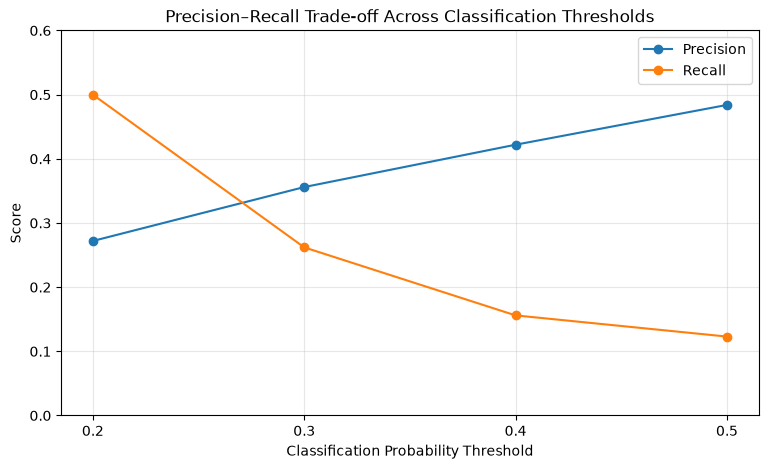

In [34]:
thresholds = [0.2, 0.3, 0.4, 0.5]
precision_values = [0.272, 0.356, 0.422, 0.484]
recall_values = [0.500, 0.262, 0.156, 0.123]

plt.figure(figsize=(9, 5))
plt.plot(thresholds, precision_values,
         marker="o", label="Precision")
plt.plot(thresholds, recall_values,
         marker="o", label="Recall")

plt.xlabel("Classification Probability Threshold")
plt.ylabel("Score")
plt.title("Precision–Recall Trade-off Across Classification Thresholds")

plt.xticks(thresholds)
plt.ylim(0, 0.6)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## 8. Introducing a chronological validation period

The next experiment revises the split to 60% training, 20% validation and 20% testing. Five rows are removed from the ends of both training and validation to separate forward target windows at the following boundaries. The volatility-label cutoff is recalculated using only the revised training portion and applied to all three portions.

This provides a dedicated validation period for subsequent experiments. It does not reverse the earlier inspection of the later test data.


In [35]:
train_end = int(len(model_df) * 0.60)
val_end = int(len(model_df) * 0.80)

train_data = model_df.iloc[:train_end].copy()
val_data = model_df.iloc[train_end:val_end].copy()
test_data = model_df.iloc[val_end:].copy()

# prevent data leakage
train_data = train_data.iloc[:-5].copy()
val_data = val_data.iloc[:-5].copy()

print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_data))

Training: 2482
Validation: 824
Testing: 830


In [36]:
# redefine threshold with new training set and apply to all three sets

vol_threshold = train_data["Future_Volatility_5d"].quantile(0.75)

for dataset in [train_data, val_data, test_data]:
    dataset["High_Volatility"] = (
        dataset["Future_Volatility_5d"] > vol_threshold
    ).astype(int)

print("New volatility threshold:", vol_threshold)

New volatility threshold: 1.002931147072383


In [37]:
# check new distributions

for name, dataset in [
    ("Training", train_data),
    ("Validation", val_data),
    ("Testing", test_data)
]:
    print(f"\n{name}")
    print("Period:", dataset.index.min(), "to", dataset.index.max())
    print("Observations:", len(dataset))
    print(
        dataset["High_Volatility"].value_counts(
            normalize=True
        )
    )



Training
Period: 2010-03-31 00:00:00 to 2020-02-07 00:00:00
Observations: 2482
High_Volatility
0    0.749799
1    0.250201
Name: proportion, dtype: float64

Validation
Period: 2020-02-18 00:00:00 to 2023-05-24 00:00:00
Observations: 824
High_Volatility
1    0.509709
0    0.490291
Name: proportion, dtype: float64

Testing
Period: 2023-06-02 00:00:00 to 2026-09-23 00:00:00
Observations: 830
High_Volatility
0    0.806024
1    0.193976
Name: proportion, dtype: float64


### Revised split and class distributions

| Portion | Forecast dates | Retained observations | High-volatility share |
|---|---|---:|---:|
| Training | 31 Mar 2010–7 Feb 2020 | 2,482 | 25.02% |
| Validation | 18 Feb 2020–24 May 2023 | 824 | 50.97% |
| Testing | 2 Jun 2023–23 Sep 2026 | 830 | 19.40% |

The new training-derived volatility cutoff is **1.002931**, lower than the initial cutoff of 1.123935. The test-period dates are unchanged, but the definition of a high-volatility label has changed, explaining why its high-volatility share differs from the earlier 14.70%.

The validation period has a much higher positive-class share than training or testing. Comparisons across these periods mix differences in market conditions and, where cutoffs change, differences in label definition.

## 9. Re-establishing the three-feature validation baseline

The next cells retrain scaled logistic regression on the revised training portion, evaluate the validation portion at the default cutoff, and plot validation probability scores. This is a new experiment under a different training period and target cutoff, so its metrics are not a like-for-like improvement over the initial test results.

In [38]:
features = [
    "Volatility_5d",
    "Volatility_20d",
    "Volatility_60d"
]

X_train = train_data[features]
y_train = train_data["High_Volatility"]

X_val = val_data[features]
y_val = val_data["High_Volatility"]

In [39]:
baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['Volatility_5d','Volatility_20d','Volatility_60d']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [40]:
val_pred = baseline_model.predict(X_val) # contains binary predictions
val_prob = baseline_model.predict_proba(X_val)[:, 1] # contains predicted probabilities of high volatility

In [41]:
print("Accuracy:", accuracy_score(y_val, val_pred))
print("Precision:", precision_score(y_val, val_pred, zero_division=0))
print("Recall:", recall_score(y_val, val_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_val, val_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_pred))

print("\nMajority-class baseline accuracy:")
print(y_val.value_counts(normalize=True).max())

Accuracy: 0.6990291262135923
Precision: 0.7704402515723271
Recall: 0.5833333333333334
ROC-AUC: 0.7702852428099953

Confusion Matrix:
[[331  73]
 [175 245]]

Majority-class baseline accuracy:
0.5097087378640777


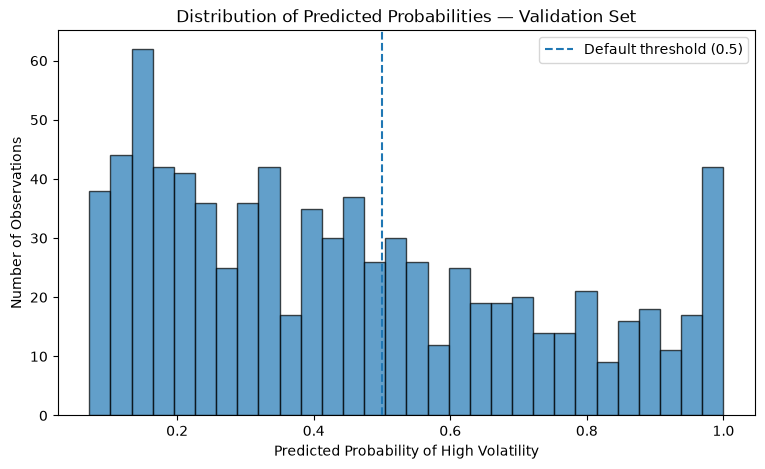

In [42]:
plt.figure(figsize=(9, 5))

plt.hist(val_prob, bins=30, edgecolor="black", alpha=0.7)

plt.axvline(
    0.5,
    linestyle="--",
    label="Default threshold (0.5)"
)

plt.xlabel("Predicted Probability of High Volatility")
plt.ylabel("Number of Observations")
plt.title("Distribution of Predicted Probabilities — Validation Set")

plt.legend()
plt.show()

### Revised baseline results

Validation accuracy is **0.6990**, precision **0.7704**, recall **0.5833** and ROC-AUC **0.7703**. The confusion matrix is `[[331, 73], [175, 245]]`.

The printed majority-class accuracy is **0.5097**. Here the majority class is high volatility; this number is a descriptive baseline computed from the validation labels, rather than a constant-class rule selected from training data. An always-low rule would achieve approximately 0.4903 accuracy on this validation portion.

The probability histogram shows a range of model scores around the default cutoff. It does not test whether those scores are calibrated probabilities.

## 10. Adding recent returns and a volatility ratio

Two features are added:

- `Return_5d`: the five-trading-day percentage change in the closing index, $100(P_t/P_{t-5}-1)$.
- `Volatility_Ratio`: trailing five-day volatility divided by trailing 60-day volatility. A ratio above one means the shorter-window estimate exceeds the longer-window estimate.

Both features use information through the current close. They are inspected, joined to the existing training and validation rows, and used alongside the original three features. Missing-value checks are shown before fitting the expanded model.

In [43]:
sp500["Return_5d"] = (
    sp500["Close"].pct_change(5) * 100
) # calculates the percentage change in the S&P 500 over the last five trading days

sp500["Volatility_Ratio"] = (
    sp500["Volatility_5d"] / sp500["Volatility_60d"]
) # compares recent volatility against a longer-term benchmark

In [44]:
sp500[[
    "Return_5d",
    "Volatility_5d",
    "Volatility_60d",
    "Volatility_Ratio"
]].tail(10)

Price,Return_5d,Volatility_5d,Volatility_60d,Volatility_Ratio
Date,,,,
2026-09-17,0.606710,0.805264,0.691264,1.164915
2026-09-18,-0.084628,0.699558,0.691064,1.012292
2026-09-21,1.899220,0.898689,0.715030,1.256854
2026-09-22,2.358509,0.813492,0.714902,1.137907
2026-09-23,2.042156,0.906527,0.708788,1.278981
2026-09-24,0.868974,0.817281,0.702323,1.163683
2026-09-25,1.214432,0.830622,0.703966,1.179919
2026-09-28,-1.043315,0.549579,0.712063,0.771812
2026-09-29,-1.208044,0.538799,0.706967,0.762127


In [45]:
sp500[[
    "Return_5d",
    "Volatility_Ratio"
]].describe()

Price,Return_5d,Volatility_Ratio
count,4206.000000,4151.000000
mean,0.252396,0.917948
std,2.227326,0.467426
min,-17.966628,0.074292
25%,-0.748239,0.572334
50%,0.412535,0.833426
75%,1.456016,1.168255
max,17.397426,3.250104


In [46]:
features_v2 = [
    "Volatility_5d",
    "Volatility_20d",
    "Volatility_60d",
    "Return_5d",
    "Volatility_Ratio"
]

In [47]:
new_features = sp500[[
    "Return_5d",
    "Volatility_Ratio"
]]

train_v2 = train_data.join(new_features)
val_v2 = val_data.join(new_features)

print(train_v2[features_v2].isna().sum())
print(val_v2[features_v2].isna().sum())

Price
Volatility_5d       0
Volatility_20d      0
Volatility_60d      0
Return_5d           0
Volatility_Ratio    0
dtype: int64
Price
Volatility_5d       0
Volatility_20d      0
Volatility_60d      0
Return_5d           0
Volatility_Ratio    0
dtype: int64


In [48]:
X_train_v2 = train_v2[features_v2]
X_val_v2 = val_v2[features_v2]

y_train_v2 = train_v2["High_Volatility"]
y_val_v2 = val_v2["High_Volatility"]

In [49]:
model_v2 = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model_v2.fit(X_train_v2, y_train_v2)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Volatility_5d','Volatility_20d','Volatility_60d','Return_5d', 'Volatility_Ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [50]:
val_pred_v2 = model_v2.predict(X_val_v2)
val_prob_v2 = model_v2.predict_proba(X_val_v2)[:, 1]

print("Accuracy:", accuracy_score(y_val_v2, val_pred_v2))
print("Precision:", precision_score(y_val_v2, val_pred_v2))
print("Recall:", recall_score(y_val_v2, val_pred_v2))
print("ROC-AUC:", roc_auc_score(y_val_v2, val_prob_v2))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_v2, val_pred_v2))

Accuracy: 0.7135922330097088
Precision: 0.772189349112426
Recall: 0.6214285714285714
ROC-AUC: 0.7802864214992927

Confusion Matrix:
[[327  77]
 [159 261]]


In [51]:
comparison = pd.DataFrame({
    "Model": ["Baseline (3 features)", "Expanded (5 features)"],
    "Accuracy": [
        accuracy_score(y_val, val_pred),
        accuracy_score(y_val_v2, val_pred_v2)
    ],
    "Precision": [
        precision_score(y_val, val_pred),
        precision_score(y_val_v2, val_pred_v2)
    ],
    "Recall": [
        recall_score(y_val, val_pred),
        recall_score(y_val_v2, val_pred_v2)
    ],
    "ROC-AUC": [
        roc_auc_score(y_val, val_prob),
        roc_auc_score(y_val_v2, val_prob_v2)
    ]
})

comparison.round(3)

,Model,Accuracy,Precision,Recall,ROC-AUC
0,Baseline (3 features),0.699,0.770,0.583,0.77
1,Expanded (5 features),0.714,0.772,0.621,0.78



### Five-feature validation results

| Model | Accuracy | Precision | Recall | ROC-AUC |
|---|---:|---:|---:|---:|
| Three-feature logistic regression | 0.699 | 0.770 | 0.583 | 0.770 |
| Five-feature logistic regression | 0.714 | 0.772 | 0.621 | 0.780 |

The expanded model improves all four displayed metrics on this validation period. It detects **261** high-volatility observations rather than **245**, while false positives rise from **73** to **77**. Recall improves by about **3.81 percentage points**.

These results motivate retaining the added features for further comparison. A single reused validation period does not establish a general improvement.

## 11. Testing class-weighted logistic regression

The next model uses the same five features and `class_weight="balanced"`. This increases the relative training weight of the minority high-volatility class. Evaluation still uses the default decision rule; the changed training objective can shift the fitted scores and therefore the precision–recall balance.

In [52]:
weighted_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    )
)

weighted_model.fit(X_train_v2, y_train_v2)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Volatility_5d','Volatility_20d','Volatility_60d','Return_5d', 'Volatility_Ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [53]:
weighted_pred = weighted_model.predict(X_val_v2)
weighted_prob = weighted_model.predict_proba(X_val_v2)[:, 1]

print("Accuracy:", accuracy_score(y_val_v2, weighted_pred))
print("Precision:", precision_score(y_val_v2, weighted_pred))
print("Recall:", recall_score(y_val_v2, weighted_pred))
print("ROC-AUC:", roc_auc_score(y_val_v2, weighted_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_v2, weighted_pred))

Accuracy: 0.7111650485436893
Precision: 0.675
Recall: 0.8357142857142857
ROC-AUC: 0.7794318717586044

Confusion Matrix:
[[235 169]
 [ 69 351]]


In [54]:
comparison.loc[len(comparison)] = {
    "Model": "Weighted Logistic Regression",
    "Accuracy": accuracy_score(y_val_v2, weighted_pred),
    "Precision": precision_score(y_val_v2, weighted_pred),
    "Recall": recall_score(y_val_v2, weighted_pred),
    "ROC-AUC": roc_auc_score(y_val_v2, weighted_prob)
}

comparison.round(3)

,Model,Accuracy,Precision,Recall,ROC-AUC
0,Baseline (3 features),0.699,0.770,0.583,0.770
1,Expanded (5 features),0.714,0.772,0.621,0.780
2,Weighted Logistic Regression,0.711,0.675,0.836,0.779


### Effect of class weighting

Weighted logistic regression achieves validation accuracy **0.7112**, precision **0.6750**, recall **0.8357** and ROC-AUC **0.7794**. Its confusion matrix is `[[235, 169], [69, 351]]`.

Compared with the unweighted five-feature model, detected positives rise from **261 to 351**, but false positives rise from **77 to 169**. Recall increases by **21.43 percentage points**, while precision falls. Ranking performance remains similar; the main observed benefit is greater sensitivity under this decision rule.

## 12. Testing a random forest

A random forest is fitted to the same five features to explore nonlinear relationships and interactions. The initial settings are 200 trees, maximum depth 5 and at least 10 observations per leaf, with a fixed random seed. These are starting choices, not the result of tuning.

In [55]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_v2, y_train_v2)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

In [56]:
rf_pred = rf_model.predict(X_val_v2)
rf_prob = rf_model.predict_proba(X_val_v2)[:, 1]

In [57]:
print("Accuracy:", accuracy_score(y_val_v2, rf_pred))
print("Precision:", precision_score(y_val_v2, rf_pred, zero_division=0))
print("Recall:", recall_score(y_val_v2, rf_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_val_v2, rf_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_v2, rf_pred))

Accuracy: 0.7184466019417476
Precision: 0.7716763005780347
Recall: 0.6357142857142857
ROC-AUC: 0.7835572842998585

Confusion Matrix:
[[325  79]
 [153 267]]


In [58]:
comparison.loc[len(comparison)] = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_val_v2, rf_pred),
    "Precision": precision_score(y_val_v2, rf_pred, zero_division=0),
    "Recall": recall_score(y_val_v2, rf_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val_v2, rf_prob)
}

comparison.round(3)

,Model,Accuracy,Precision,Recall,ROC-AUC
0,Baseline (3 features),0.699,0.770,0.583,0.770
1,Expanded (5 features),0.714,0.772,0.621,0.780
2,Weighted Logistic Regression,0.711,0.675,0.836,0.779
3,Random Forest,0.718,0.772,0.636,0.784


### Initial random forest results

Validation accuracy is **0.7184**, precision **0.7717**, recall **0.6357** and ROC-AUC **0.7836**. The confusion matrix is `[[325, 79], [153, 267]]`.

The forest performs slightly better than unweighted five-feature logistic regression on this particular validation period, including detecting **267 rather than 261** positives. The small differences and repeated use of the validation period motivate checking several chronological periods before choosing a model.

## 13. Expanding-window validation

The development dataset is reconstructed from all eligible forecast dates before the existing test start date. It contains **3,316 observations**, from **31 March 2010 to 1 June 2023**.

`TimeSeriesSplit` creates four expanding training windows, each followed by a five-observation gap and a 400-observation validation window. Models are refitted once per fold. Each fold's volatility-label cutoff is calculated from that fold's training targets; logistic-regression scaling is also fitted within the training fold.

This design tests the procedure across several historical periods. Its fold-specific labels mean that “high volatility” does not have one identical numerical cutoff across all folds.

In [59]:
development_df = sp500.loc[
    sp500.index < test_data.index.min(),
    features_v2 + ["Future_Volatility_5d"]
].dropna().copy()

print("Observations:", len(development_df))
print("Start:", development_df.index.min())
print("End:", development_df.index.max())

Observations: 3316
Start: 2010-03-31 00:00:00
End: 2023-06-01 00:00:00


In [60]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(
    n_splits=4,
    test_size=400,
    gap=5
)

In [61]:
for fold, (train_idx, val_idx) in enumerate(
    tscv.split(development_df), start=1
):
    fold_train = development_df.iloc[train_idx]
    fold_val = development_df.iloc[val_idx]

    print(f"\nFold {fold}")
    print(
        "Training:",
        fold_train.index.min().date(),
        "to",
        fold_train.index.max().date()
    )
    print(
        "Validation:",
        fold_val.index.min().date(),
        "to",
        fold_val.index.max().date()
    )
    print("Training observations:", len(fold_train))
    print("Validation observations:", len(fold_val))


Fold 1
Training: 2010-03-31 to 2017-01-13
Validation: 2017-01-24 to 2018-08-23
Training observations: 1711
Validation observations: 400

Fold 2
Training: 2010-03-31 to 2018-08-16
Validation: 2018-08-24 to 2020-03-27
Training observations: 2111
Validation observations: 400

Fold 3
Training: 2010-03-31 to 2020-03-20
Validation: 2020-03-30 to 2021-10-27
Training observations: 2511
Validation observations: 400

Fold 4
Training: 2010-03-31 to 2021-10-20
Validation: 2021-10-28 to 2023-06-01
Training observations: 2911
Validation observations: 400


### Walk-forward schedule

| Fold | Training end | Training rows | Validation dates | Validation rows |
|---|---|---:|---|---:|
| 1 | 13 Jan 2017 | 1,711 | 24 Jan 2017–23 Aug 2018 | 400 |
| 2 | 16 Aug 2018 | 2,111 | 24 Aug 2018–27 Mar 2020 | 400 |
| 3 | 20 Mar 2020 | 2,511 | 30 Mar 2020–27 Oct 2021 | 400 |
| 4 | 20 Oct 2021 | 2,911 | 28 Oct 2021–1 Jun 2023 | 400 |

Every training window starts on 31 March 2010. Earlier validation observations can become training observations in later folds, as expected in an expanding-window design. The gap separates training labels from the next validation start; it does not remove dependence between consecutive validation targets.

**Development-boundary qualification:** the development dataset is selected by forecast date, not target end date. Its last five targets use returns extending into the later evaluation period. Thus, the end of fold 4 is not fully separated from that later period for model selection. The final training fit later removes these five rows, but that does not undo their use during development.

The next cells compare the original five-feature logistic regression and random forest using this schedule.

In [62]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
)

walk_forward_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(development_df), start=1
):
    fold_train = development_df.iloc[train_idx].copy()
    fold_val = development_df.iloc[val_idx].copy()

    # Calculate the threshold using training data only
    fold_threshold = fold_train[
        "Future_Volatility_5d"
    ].quantile(0.75)

    # Create classification labels
    y_train_fold = (
        fold_train["Future_Volatility_5d"] > fold_threshold
    ).astype(int)

    y_val_fold = (
        fold_val["Future_Volatility_5d"] > fold_threshold
    ).astype(int)

    X_train_fold = fold_train[features_v2]
    X_val_fold = fold_val[features_v2]

    models = {
        "Logistic Regression": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1000)
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=200,
            max_depth=5,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=-1
        )
    }

    for model_name, model in models.items():
        model.fit(X_train_fold, y_train_fold)

        predictions = model.predict(X_val_fold)
        probabilities = model.predict_proba(
            X_val_fold
        )[:, 1]

        walk_forward_results.append({
            "Fold": fold,
            "Model": model_name,
            "Accuracy": accuracy_score(
                y_val_fold, predictions
            ),
            "Precision": precision_score(
                y_val_fold, predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_val_fold, predictions,
                zero_division=0
            ),
            "ROC-AUC": (
                roc_auc_score(y_val_fold, probabilities)
                if y_val_fold.nunique() == 2
                else float("nan")
            ),
            "High_Volatility_Rate": y_val_fold.mean(),
            "Volatility_Threshold": fold_threshold
        })

walk_forward_df = pd.DataFrame(walk_forward_results)

walk_forward_df.round(3)

,Fold,Model,Accuracy,Precision,Recall,ROC-AUC,High_Volatility_Rate,Volatility_Threshold
0,1,Logistic Regression,0.915,0.440,0.355,0.929,0.078,1.059
1,1,Random Forest,0.922,0.500,0.452,0.894,0.078,1.059
2,2,Logistic Regression,0.770,0.714,0.496,0.828,0.328,0.997
3,2,Random Forest,0.775,0.736,0.489,0.831,0.328,0.997
4,3,Logistic Regression,0.772,0.673,0.562,0.772,0.320,1.014
5,3,Random Forest,0.770,0.673,0.547,0.794,0.320,1.014
6,4,Logistic Regression,0.622,0.802,0.522,0.730,0.622,1.031
7,4,Random Forest,0.632,0.783,0.566,0.702,0.622,1.031


In [63]:
walk_forward_summary = (
    walk_forward_df
    .groupby("Model")[
        ["Accuracy", "Precision", "Recall", "ROC-AUC"]
    ]
    .agg(["mean", "std"])
)

walk_forward_summary.round(3)

Accuracy        Precision        Recall        ROC-AUC  \
                        mean    std      mean    std   mean    std    mean   
Model                                                                        
Logistic Regression    0.770  0.119     0.657  0.155  0.484  0.090   0.815   
Random Forest          0.775  0.118     0.673  0.124  0.513  0.053   0.805   

                            
                       std  
Model                       
Logistic Regression  0.086  
Random Forest        0.080

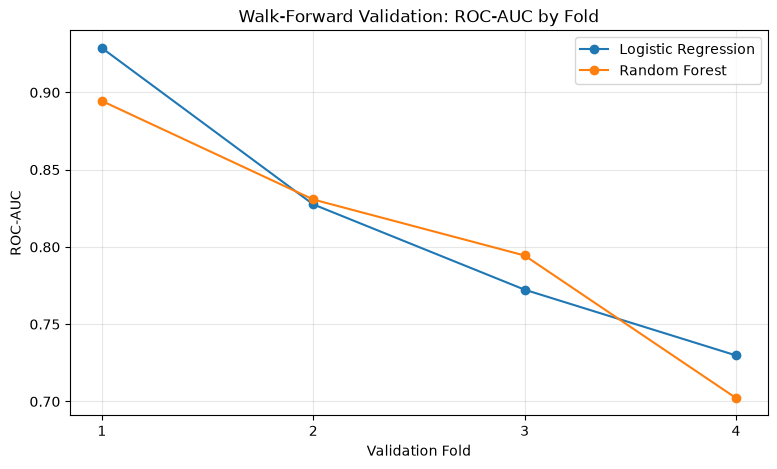

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for model_name, group in walk_forward_df.groupby("Model"):
    plt.plot(
        group["Fold"],
        group["ROC-AUC"],
        marker="o",
        label=model_name
    )

plt.xlabel("Validation Fold")
plt.ylabel("ROC-AUC")
plt.title("Walk-Forward Validation: ROC-AUC by Fold")
plt.xticks([1, 2, 3, 4])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [65]:
walk_forward_df[
    [
        "Fold",
        "Model",
        "High_Volatility_Rate",
        "Volatility_Threshold"
    ]
].round(3)

,Fold,Model,High_Volatility_Rate,Volatility_Threshold
0,1,Logistic Regression,0.078,1.059
1,1,Random Forest,0.078,1.059
2,2,Logistic Regression,0.328,0.997
3,2,Random Forest,0.328,0.997
4,3,Logistic Regression,0.320,1.014
5,3,Random Forest,0.320,1.014
6,4,Logistic Regression,0.622,1.031
7,4,Random Forest,0.622,1.031


### Initial walk-forward findings

| Model | Mean ROC-AUC | Fold standard deviation | Mean accuracy | Mean recall |
|---|---:|---:|---:|---:|
| Logistic regression | 0.815 | 0.086 | 0.770 | 0.484 |
| Initial random forest | 0.805 | 0.080 | 0.775 | 0.513 |

Logistic-regression fold ROC-AUC values are **0.929, 0.828, 0.772 and 0.730**. Random-forest values are **0.894, 0.831, 0.794 and 0.702**. Performance varies substantially across the examined periods.

Validation high-volatility prevalence changes from approximately **7.8%** to **32.8%**, **32.0%** and **62.2%**; corresponding fold label cutoffs are approximately **1.059, 0.997, 1.014 and 1.031**. These shifts help explain why accuracy, precision and recall should be examined alongside ROC-AUC. They do not independently establish the cause of performance changes.

The summaries are unweighted means of fold metrics. Their standard deviations describe variation across four historical folds, not confidence intervals or significance tests.

## 14. Tuning random forest hyperparameters

The next diagnostic calculates a fixed cutoff from the earlier 60% training portion and creates a `High_Volatility` column in the development dataset. The subsequent tuning loop **does not use this fixed-label column**: it recalculates a training-only volatility cutoff separately within each fold.

The grid contains **24 configurations**: 100 or 200 trees, maximum depth 3, 5, 8 or 12, and minimum leaf size 5, 10 or 20. Configurations are ranked by mean ROC-AUC across the same four folds.

In [66]:
fixed_threshold = train_data[
    "Future_Volatility_5d"
].quantile(0.75)

print("Fixed volatility threshold:", fixed_threshold)

development_df["High_Volatility"] = (
    development_df["Future_Volatility_5d"] > fixed_threshold
).astype(int)

print(development_df["High_Volatility"].value_counts(normalize=True))

Fixed volatility threshold: 1.002931147072383
High_Volatility
0    0.685766
1    0.314234
Name: proportion, dtype: float64


In [67]:
from itertools import product

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 8, 12],
    "min_samples_leaf": [5, 10, 20]
}

param_combinations = list(product(
    param_grid["n_estimators"],
    param_grid["max_depth"],
    param_grid["min_samples_leaf"]
))

print("Number of combinations:", len(param_combinations))
print("First five combinations:")
print(param_combinations[:5])

Number of combinations: 24
First five combinations:
[(100, 3, 5), (100, 3, 10), (100, 3, 20), (100, 5, 5), (100, 5, 10)]


In [68]:
tuning_results = []

for n_trees, depth, min_leaf in param_combinations:

    fold_aucs = []

    for train_idx, val_idx in tscv.split(development_df):

        fold_train = development_df.iloc[train_idx]
        fold_val = development_df.iloc[val_idx]

        # Training-only volatility threshold
        threshold = fold_train[
            "Future_Volatility_5d"
        ].quantile(0.75)

        y_train = (
            fold_train["Future_Volatility_5d"] > threshold
        ).astype(int)

        y_val = (
            fold_val["Future_Volatility_5d"] > threshold
        ).astype(int)

        model = RandomForestClassifier(
            n_estimators=n_trees,
            max_depth=depth,
            min_samples_leaf=min_leaf,
            random_state=42,
            n_jobs=-1
        )

        model.fit(fold_train[features_v2], y_train)

        probabilities = model.predict_proba(
            fold_val[features_v2]
        )[:, 1]

        if y_val.nunique() == 2:
            auc = roc_auc_score(y_val, probabilities)
            fold_aucs.append(auc)

    tuning_results.append({
        "n_estimators": n_trees,
        "max_depth": depth,
        "min_samples_leaf": min_leaf,
        "Mean_ROC_AUC": np.mean(fold_aucs),
        "Std_ROC_AUC": np.std(fold_aucs)
    })

tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    "Mean_ROC_AUC",
    ascending=False
).reset_index(drop=True)

tuning_df.head(10).round(4)

,n_estimators,max_depth,min_samples_leaf,Mean_ROC_AUC,Std_ROC_AUC
0,200,3,20,0.8094,0.0681
1,200,3,10,0.8086,0.0666
2,200,3,5,0.8084,0.0661
3,100,3,20,0.8083,0.0654
4,100,3,5,0.8079,0.0648
5,100,3,10,0.8074,0.0649
6,200,5,10,0.8055,0.0695
7,100,5,10,0.8054,0.0712
8,200,5,20,0.8048,0.0683
9,100,5,20,0.8025,0.0664


In [69]:
original_rf = tuning_df[
    (tuning_df["n_estimators"] == 200) &
    (tuning_df["max_depth"] == 5) &
    (tuning_df["min_samples_leaf"] == 10)
]

print("Original configuration:")
display(original_rf.round(4))

print("\nBest configuration:")
display(tuning_df.head(1).round(4))

Original configuration:


,n_estimators,max_depth,min_samples_leaf,Mean_ROC_AUC,Std_ROC_AUC
6,200,5,10,0.8055,0.0695



Best configuration:


,n_estimators,max_depth,min_samples_leaf,Mean_ROC_AUC,Std_ROC_AUC
0,200,3,20,0.8094,0.0681


### Tuning results and selection limits

The highest observed mean ROC-AUC is **0.8094**, using **200 trees, maximum depth 3 and minimum leaf size 20**. The original configuration scores **0.8055**, an increase of approximately **0.0039**.

This is a small improvement on the same folds used for choosing the configuration. It is not an independently validated tuning gain. The tuning table uses NumPy's population standard deviation (`ddof=0`), whereas the grouped pandas summaries use sample standard deviation (`ddof=1`); this explains why reported fold variability differs between tables for the same configuration.

## 15. Comparing the retained candidate models

Unweighted logistic regression, class-weighted logistic regression and the tuned random forest are compared on the same four folds. All use the original five features and their default classification decision rule. The forest settings were selected using these folds, so this comparison remains part of development.

In [70]:
candidate_models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "Weighted Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        )
    ),

    "Tuned Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=20,
        random_state=42,
        n_jobs=-1
    )
}

In [71]:
candidate_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(development_df), start=1
):
    fold_train = development_df.iloc[train_idx]
    fold_val = development_df.iloc[val_idx]

    threshold = fold_train[
        "Future_Volatility_5d"
    ].quantile(0.75)

    X_train = fold_train[features_v2]
    X_val = fold_val[features_v2]

    y_train = (
        fold_train["Future_Volatility_5d"] > threshold
    ).astype(int)

    y_val = (
        fold_val["Future_Volatility_5d"] > threshold
    ).astype(int)

    for model_name, model in candidate_models.items():

        model.fit(X_train, y_train)

        predictions = model.predict(X_val)
        probabilities = model.predict_proba(X_val)[:, 1]

        candidate_results.append({
            "Fold": fold,
            "Model": model_name,
            "Accuracy": accuracy_score(y_val, predictions),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(
                y_val, probabilities
            )
        })

candidate_df = pd.DataFrame(candidate_results)

candidate_df.round(3)

,Fold,Model,Accuracy,Precision,Recall,ROC-AUC
0,1,Logistic Regression,0.915,0.440,0.355,0.929
1,1,Weighted Logistic Regression,0.902,0.431,0.806,0.929
2,1,Tuned Random Forest,0.915,0.435,0.323,0.903
3,2,Logistic Regression,0.770,0.714,0.496,0.828
4,2,Weighted Logistic Regression,0.748,0.597,0.702,0.827
5,2,Tuned Random Forest,0.765,0.723,0.458,0.837
6,3,Logistic Regression,0.772,0.673,0.562,0.772
7,3,Weighted Logistic Regression,0.708,0.531,0.742,0.773
8,3,Tuned Random Forest,0.762,0.677,0.492,0.777
9,4,Logistic Regression,0.622,0.802,0.522,0.730


In [72]:
candidate_summary = (
    candidate_df
    .groupby("Model")[
        ["Accuracy", "Precision", "Recall", "ROC-AUC"]
    ]
    .agg(["mean", "std"])
)

candidate_summary.round(3)

Accuracy        Precision        Recall         \
                                 mean    std      mean    std   mean    std   
Model                                                                         
Logistic Regression             0.770  0.119     0.657  0.155  0.484  0.090   
Tuned Random Forest             0.771  0.113     0.662  0.162  0.455  0.095   
Weighted Logistic Regression    0.766  0.093     0.570  0.122  0.779  0.071   

                             ROC-AUC         
                                mean    std  
Model                                        
Logistic Regression            0.815  0.086  
Tuned Random Forest            0.809  0.079  
Weighted Logistic Regression   0.814  0.087

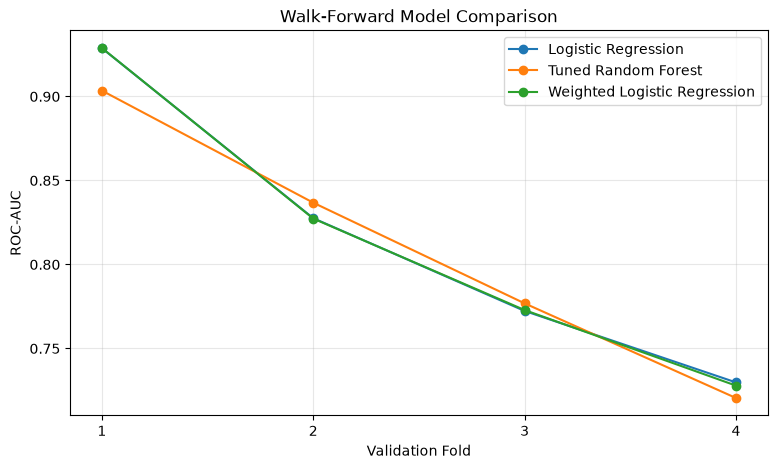

In [73]:
plt.figure(figsize=(9, 5))

for model_name, group in candidate_df.groupby("Model"):
    plt.plot(
        group["Fold"],
        group["ROC-AUC"],
        marker="o",
        label=model_name
    )

plt.xlabel("Validation Fold")
plt.ylabel("ROC-AUC")
plt.title("Walk-Forward Model Comparison")
plt.xticks([1, 2, 3, 4])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Candidate comparison

| Model | Mean ROC-AUC | Mean precision | Mean recall |
|---|---:|---:|---:|
| Unweighted logistic regression | 0.815 | 0.657 | 0.484 |
| Weighted logistic regression | 0.814 | 0.570 | 0.779 |
| Tuned random forest | 0.809 | 0.662 | 0.455 |

Unweighted logistic regression has the highest mean ROC-AUC in this comparison, but the differences are small. Weighted logistic regression offers greater recall at lower precision under the default rule. These results support carrying the simpler unweighted model forward, without establishing statistical or universal superiority.

## 16. Selecting a probability cutoff using development predictions

The notebook regenerates one logistic-regression probability score for each validation date, producing **1,600 out-of-fold development predictions** with no missing entries. Each prediction comes from a model trained on earlier observations, but the same validation data have already informed model development.

Cutoffs from **0.20 to 0.60**, in increments of 0.05, are compared using pooled accuracy, precision, recall and F1. F1 is the harmonic mean of precision and recall. The selection is restricted to this grid; no continuous optimisation or application-specific false-alert cost is implemented.

In [74]:
oos_predictions = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(development_df), start=1
):
    fold_train = development_df.iloc[train_idx]
    fold_val = development_df.iloc[val_idx]

    threshold = fold_train[
        "Future_Volatility_5d"
    ].quantile(0.75)

    X_train = fold_train[features_v2]
    X_val = fold_val[features_v2]

    y_train = (
        fold_train["Future_Volatility_5d"] > threshold
    ).astype(int)

    y_val = (
        fold_val["Future_Volatility_5d"] > threshold
    ).astype(int)

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    )

    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_val)[:, 1]

    fold_predictions = pd.DataFrame({
        "Fold": fold,
        "Actual": y_val.values,
        "Probability": probabilities
    }, index=fold_val.index)

    oos_predictions.append(fold_predictions)

oos_df = pd.concat(oos_predictions)

oos_df.head()

,Fold,Actual,Probability
Date,,,
2017-01-24,1,0,0.056575
2017-01-25,1,0,0.057554
2017-01-26,1,0,0.047459
2017-01-27,1,0,0.052462
2017-01-30,1,0,0.069543


In [75]:
print(oos_df.shape)
print(oos_df.isna().sum())

(1600, 3)
Fold           0
Actual         0
Probability    0
dtype: int64


In [76]:
from sklearn.metrics import f1_score

threshold_results = []

for cutoff in np.arange(0.20, 0.65, 0.05):

    predictions = (
        oos_df["Probability"] >= cutoff
    ).astype(int)

    threshold_results.append({
        "Cutoff": round(cutoff, 2),
        "Accuracy": accuracy_score(
            oos_df["Actual"], predictions
        ),
        "Precision": precision_score(
            oos_df["Actual"], predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            oos_df["Actual"], predictions,
            zero_division=0
        ),
        "F1": f1_score(
            oos_df["Actual"], predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(3)

,Cutoff,Accuracy,Precision,Recall,F1
0,0.20,0.738,0.575,0.848,0.685
1,0.25,0.769,0.623,0.796,0.699
2,0.30,0.766,0.634,0.720,0.674
3,0.35,0.778,0.665,0.686,0.676
4,0.40,0.779,0.690,0.627,0.657
5,0.45,0.774,0.705,0.568,0.629
6,0.50,0.770,0.722,0.516,0.602
7,0.55,0.766,0.736,0.477,0.579
8,0.60,0.762,0.752,0.438,0.553


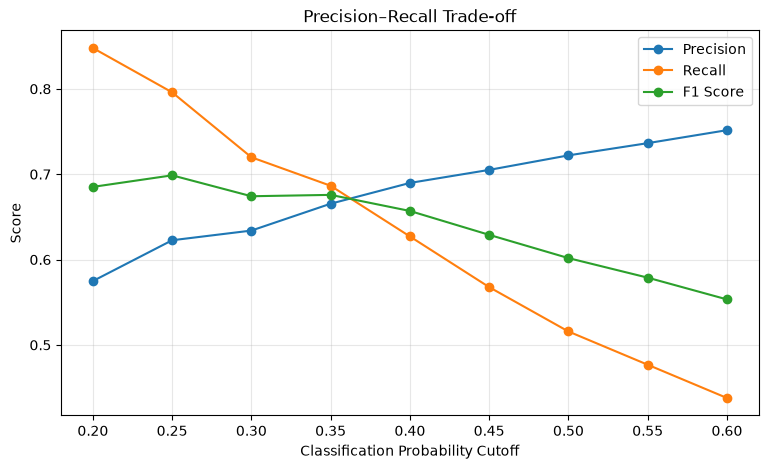

In [77]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Cutoff"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Cutoff"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Cutoff"],
    threshold_df["F1"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Probability Cutoff")
plt.ylabel("Score")
plt.title("Precision–Recall Trade-off")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Pooled cutoff results

The **0.25 cutoff** gives the highest pooled F1 among the tested values:

| Cutoff | Accuracy | Precision | Recall | F1 |
|---|---:|---:|---:|---:|
| 0.25 | 0.769 | 0.623 | 0.796 | 0.699 |
| 0.50 | 0.770 | 0.722 | 0.516 | 0.602 |

The lower cutoff prioritises detection at the cost of more false alerts. It is retained as a development choice, not an independently established optimal operating point. Neither this selection nor ROC-AUC demonstrates probability calibration.

Pooled precision, recall and F1 are calculated after combining all predictions. They differ from arithmetic means of fold-level scores because the number of positives and alerts varies by fold, and the fold label cutoffs also differ.

## 17. Checking the chosen cutoff across folds

The next cells compare 0.25 and 0.50 separately within each fold, plot fold F1 scores and summarise their means and standard deviations. This checks whether the pooled preference is concentrated in one period, while continuing to reuse development data.

In [78]:
fold_threshold_results = []

for fold in sorted(oos_df["Fold"].unique()):

    fold_data = oos_df[oos_df["Fold"] == fold]

    for cutoff in [0.25, 0.50]:

        predictions = (
            fold_data["Probability"] >= cutoff
        ).astype(int)

        fold_threshold_results.append({
            "Fold": fold,
            "Cutoff": cutoff,
            "Accuracy": accuracy_score(
                fold_data["Actual"], predictions
            ),
            "Precision": precision_score(
                fold_data["Actual"], predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                fold_data["Actual"], predictions,
                zero_division=0
            ),
            "F1": f1_score(
                fold_data["Actual"], predictions,
                zero_division=0
            )
        })

fold_threshold_df = pd.DataFrame(fold_threshold_results)

fold_threshold_df.round(3)

,Fold,Cutoff,Accuracy,Precision,Recall,F1
0,1,0.25,0.902,0.431,0.806,0.562
1,1,0.50,0.915,0.440,0.355,0.393
2,2,0.25,0.758,0.609,0.725,0.662
3,2,0.50,0.770,0.714,0.496,0.586
4,3,0.25,0.710,0.533,0.750,0.623
5,3,0.50,0.772,0.673,0.562,0.613
6,4,0.25,0.705,0.722,0.855,0.783
7,4,0.50,0.622,0.802,0.522,0.633


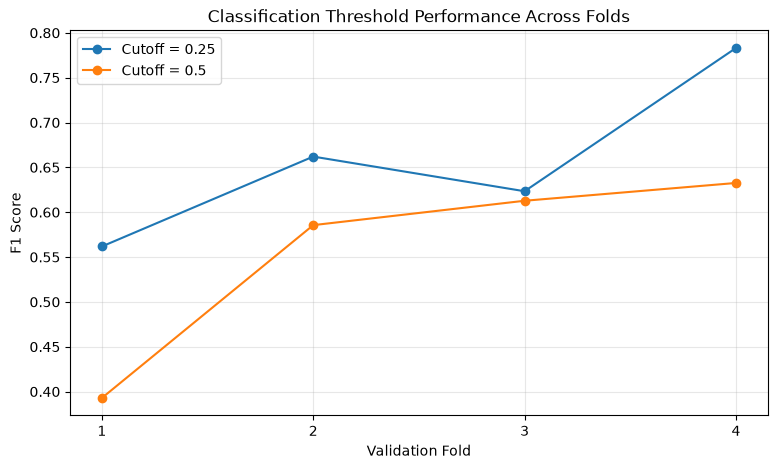

In [79]:
plt.figure(figsize=(9, 5))

for cutoff, group in fold_threshold_df.groupby("Cutoff"):

    plt.plot(
        group["Fold"],
        group["F1"],
        marker="o",
        label=f"Cutoff = {cutoff}"
    )

plt.xlabel("Validation Fold")
plt.ylabel("F1 Score")
plt.title("Classification Threshold Performance Across Folds")
plt.xticks([1, 2, 3, 4])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [80]:
fold_threshold_summary = (
    fold_threshold_df
    .groupby("Cutoff")[
        ["Accuracy", "Precision", "Recall", "F1"]
    ]
    .agg(["mean", "std"])
)

fold_threshold_summary.round(3)

Accuracy        Precision        Recall            F1       
           mean    std      mean    std   mean    std   mean    std
Cutoff                                                             
0.25      0.769  0.092     0.574  0.123  0.784  0.058  0.658  0.093
0.50      0.770  0.119     0.657  0.155  0.484  0.090  0.556  0.110

### Fold-level cutoff comparison

| Cutoff | Mean accuracy | Mean precision | Mean recall | Mean F1 |
|---|---:|---:|---:|---:|
| 0.25 | 0.769 | 0.574 | 0.784 | 0.658 |
| 0.50 | 0.770 | 0.657 | 0.484 | 0.556 |

The 0.25 cutoff improves recall and F1 in **all four examined folds**. Its F1 values are **0.562, 0.662, 0.623 and 0.783**, compared with **0.393, 0.586, 0.613 and 0.633** at 0.50. Accuracy is lower in the first three folds and higher in the fourth.

This supports a more sensitive alert rule for the current research objective. It does not establish stable precision or performance under future market conditions, and it is not a fresh validation of the selected cutoff.

## 18. Extending the feature set and model comparison

Two additional features are constructed:

- `Downside_Volatility_20d`: the rolling 20-day sample standard deviation after positive daily returns are replaced by zero. This is the precise implemented measure, rather than a standard deviation calculated only over negative-return days or a root-mean-square downside deviation.
- `Volatility_Momentum`: current five-day volatility minus its value five trading days earlier.

The seven-feature development dataset retains **3,316 observations** and has no missing values in the selected features. The next experiment compares five-feature logistic regression, seven-feature logistic regression and seven-feature histogram gradient boosting. Classification uses the retained probability cutoff of 0.25; ROC-AUC continues to use continuous scores.

In [81]:
# Downside volatility
sp500["Negative_Return"] = sp500["Daily_Return"].clip(upper=0)

sp500["Downside_Volatility_20d"] = (
    sp500["Negative_Return"].rolling(20).std()
)

# Volatility momentum
sp500["Volatility_Momentum"] = (
    sp500["Volatility_5d"]
    - sp500["Volatility_5d"].shift(5)
)

# Inspect the new features
sp500[
    ["Downside_Volatility_20d", "Volatility_Momentum"]
].describe()

Price,Downside_Volatility_20d,Volatility_Momentum
count,4191.000000,4201.000000
mean,0.530895,0.000094
std,0.374612,0.593768
min,0.060809,-4.644585
25%,0.297046,-0.278030
50%,0.442215,-0.006666
75%,0.666425,0.274995
max,3.563718,5.032478


In [82]:
# Original five features
features_v2 = [
    "Volatility_5d",
    "Volatility_20d",
    "Volatility_60d",
    "Return_5d",
    "Volatility_Ratio"
]

# Two additional features
features_v3 = features_v2 + [
    "Downside_Volatility_20d",
    "Volatility_Momentum"
]

# Add new features to development dataset
development_df = development_df.join(
    sp500[
        ["Downside_Volatility_20d", "Volatility_Momentum"]
    ]
)

print("Development observations:", len(development_df))
print("Number of features:", len(features_v3))
print("\nMissing values:")
print(development_df[features_v3].isna().sum())

Development observations: 3316
Number of features: 7

Missing values:
Price
Volatility_5d              0
Volatility_20d             0
Volatility_60d             0
Return_5d                  0
Volatility_Ratio           0
Downside_Volatility_20d    0
Volatility_Momentum        0
dtype: int64


In [83]:
from sklearn.ensemble import HistGradientBoostingClassifier

In [84]:
advanced_models = {
    "Logistic Regression (5 features)": (
        make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1000)
        ),
        features_v2
    ),

    "Logistic Regression (7 features)": (
        make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1000)
        ),
        features_v3
    ),

    "Gradient Boosting (7 features)": (
        HistGradientBoostingClassifier(
            max_iter=100,
            learning_rate=0.05,
            max_leaf_nodes=7,
            min_samples_leaf=20,
            random_state=42
        ),
        features_v3
    )
}

In [85]:
advanced_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(development_df), start=1
):
    fold_train = development_df.iloc[train_idx]
    fold_val = development_df.iloc[val_idx]

    threshold = fold_train[
        "Future_Volatility_5d"
    ].quantile(0.75)

    y_train = (
        fold_train["Future_Volatility_5d"] > threshold
    ).astype(int)

    y_val = (
        fold_val["Future_Volatility_5d"] > threshold
    ).astype(int)

    for model_name, (model, feature_list) in advanced_models.items():

        model.fit(
            fold_train[feature_list],
            y_train
        )

        probabilities = model.predict_proba(
            fold_val[feature_list]
        )[:, 1]

        predictions = (probabilities >= 0.25).astype(int)

        advanced_results.append({
            "Fold": fold,
            "Model": model_name,
            "Accuracy": accuracy_score(y_val, predictions),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_val, predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(
                y_val, probabilities
            )
        })

advanced_df = pd.DataFrame(advanced_results)

advanced_df.round(3)

,Fold,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,1,Logistic Regression (5 features),0.902,0.431,0.806,0.562,0.929
1,1,Logistic Regression (7 features),0.880,0.365,0.742,0.489,0.915
2,1,Gradient Boosting (7 features),0.882,0.371,0.742,0.495,0.895
3,2,Logistic Regression (5 features),0.758,0.609,0.725,0.662,0.828
4,2,Logistic Regression (7 features),0.748,0.595,0.718,0.651,0.828
5,2,Gradient Boosting (7 features),0.768,0.620,0.748,0.678,0.840
6,3,Logistic Regression (5 features),0.710,0.533,0.750,0.623,0.772
7,3,Logistic Regression (7 features),0.700,0.522,0.742,0.613,0.767
8,3,Gradient Boosting (7 features),0.695,0.516,0.758,0.614,0.783
9,4,Logistic Regression (5 features),0.705,0.722,0.855,0.783,0.730


In [86]:
advanced_summary = (
    advanced_df
    .groupby("Model")[
        ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
    ]
    .agg(["mean", "std"])
)

advanced_summary.round(3)

Accuracy        Precision        Recall  \
                                     mean    std      mean    std   mean   
Model                                                                      
Gradient Boosting (7 features)      0.762  0.086     0.558  0.151  0.775   
Logistic Regression (5 features)    0.769  0.092     0.574  0.123  0.784   
Logistic Regression (7 features)    0.759  0.083     0.553  0.152  0.761   

                                            F1        ROC-AUC         
                                    std   mean    std    mean    std  
Model                                                                 
Gradient Boosting (7 features)    0.051  0.642  0.120   0.812  0.072  
Logistic Regression (5 features)  0.058  0.658  0.093   0.815  0.086  
Logistic Regression (7 features)  0.056  0.634  0.121   0.813  0.076

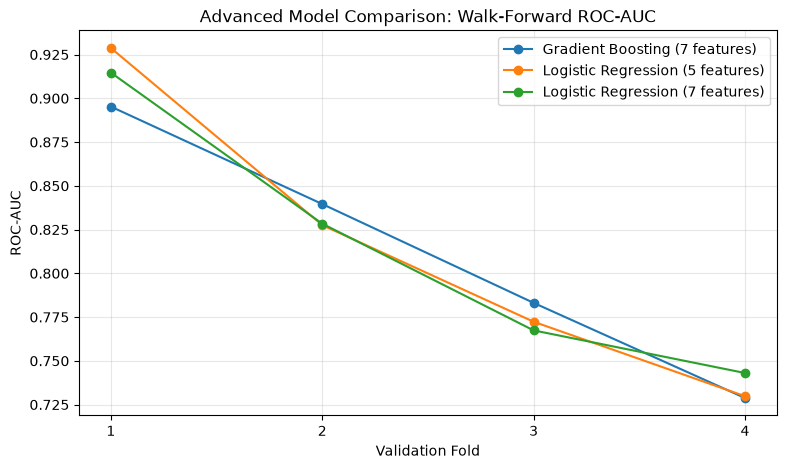

In [87]:
plt.figure(figsize=(9, 5))

for model_name, group in advanced_df.groupby("Model"):
    plt.plot(
        group["Fold"],
        group["ROC-AUC"],
        marker="o",
        label=model_name
    )

plt.xlabel("Validation Fold")
plt.ylabel("ROC-AUC")
plt.title("Advanced Model Comparison: Walk-Forward ROC-AUC")
plt.xticks([1, 2, 3, 4])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Additional features and gradient boosting results

| Model | Mean ROC-AUC | Mean F1 at 0.25 | Mean recall at 0.25 |
|---|---:|---:|---:|
| Logistic regression, five features | 0.815 | 0.658 | 0.784 |
| Logistic regression, seven features | 0.813 | 0.634 | 0.761 |
| Gradient boosting, seven features | 0.812 | 0.642 | 0.775 |

Neither the two additional features nor the tested gradient-boosting specification improves average ROC-AUC or F1 over the five-feature logistic model. Results vary by fold, and only the implemented specifications are compared. A shared numerical cutoff need not represent the same calibrated event probability across different classifiers.

### 18.1. Introducing a GARCH(1,1) benchmark

The next cells install and import `arch`, fit a constant-mean GARCH(1,1) with normally distributed innovations on the first training fold, and inspect five daily variance forecasts. Returns remain in percentage units, so forecast variances are in squared percentage-point units.

This benchmark models conditional return variance directly. It is not trained to classify the binary target used by the machine-learning models.

In [88]:
%pip install arch


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [89]:
from arch import arch_model

In [90]:
train_idx, val_idx = list(tscv.split(development_df))[0]

garch_train = development_df.iloc[train_idx]

garch_returns = sp500.loc[
    garch_train.index, "Daily_Return"
].dropna()

garch_model = arch_model(
    garch_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

garch_fit = garch_model.fit(disp="off")

print(garch_fit.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:           Daily_Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -2162.59
Distribution:                  Normal   AIC:                           4333.18
Method:            Maximum Likelihood   BIC:                           4354.96
                                        No. Observations:                 1711
Date:                Sun, Oct 25 2026   Df Residuals:                     1710
Time:                        17:51:42   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.0680  1.859e-02      3.657  2.555e-04 [3.154e-0

In [91]:
garch_forecast = garch_fit.forecast(
    horizon=5,
    reindex=False
)

forecast_variances = (
    garch_forecast.variance.iloc[-1]
)

print("Forecast daily variances:")
print(forecast_variances)

print("\nForecast daily volatilities:")
print(np.sqrt(forecast_variances))

Forecast daily variances:
h.1    0.306448
h.2    0.336490
h.3    0.365060
h.4    0.392232
h.5    0.418073
Name: 2017-01-13 00:00:00, dtype: float64

Forecast daily volatilities:
h.1    0.553577
h.2    0.580077
h.3    0.604202
h.4    0.626284
h.5    0.646585
Name: 2017-01-13 00:00:00, dtype: float64


### Illustrative GARCH fit and forecast

The first-fold fit reports approximately **0.1484** for the shock coefficient and **0.8026** for the persistence coefficient. Their sum is about **0.951**, consistent with persistent conditional variance under this fitted specification.

The displayed one- through five-step daily volatility forecasts are approximately **0.5536, 0.5801, 0.6042, 0.6263 and 0.6466**. They originate at the final training date, **13 January 2017**, rather than the first validation date.

The next cell repeats this end-of-training forecast for each fold and summarises it as the square root of mean forecast variance. These four values are illustrative forecasts, not a daily validation backtest: their five-day horizons lie in the gap before each validation window.

In [92]:
garch_fold_forecasts = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(development_df), start=1
):
    fold_train = development_df.iloc[train_idx]
    fold_val = development_df.iloc[val_idx]

    returns = sp500.loc[
        fold_train.index, "Daily_Return"
    ].dropna()

    model = arch_model(
        returns,
        mean="Constant",
        vol="GARCH",
        p=1,
        q=1,
        dist="normal"
    )

    fitted = model.fit(disp="off")

    forecast = fitted.forecast(
        horizon=5,
        reindex=False
    )

    variances = forecast.variance.iloc[-1]

    forecast_volatility = np.sqrt(
        variances.mean()
    )

    garch_fold_forecasts.append({
        "Fold": fold,
        "Training_End": fold_train.index[-1],
        "Validation_Start": fold_val.index[0],
        "Forecast_Volatility": forecast_volatility
    })

garch_fold_df = pd.DataFrame(garch_fold_forecasts)

garch_fold_df

,Fold,Training_End,Validation_Start,Forecast_Volatility
0,1,2017-01-13,2017-01-24,0.603043
1,2,2018-08-16,2018-08-24,0.702751
2,3,2020-03-20,2020-03-30,5.454411
3,4,2021-10-20,2021-10-28,0.793591


### 18.2. Updating GARCH forecasts through validation

The following function replaces the illustrative fold-start summaries with a forecast for **each validation date**. Parameters are fitted once on the fold's training returns and held fixed. Conditional variance is then updated sequentially using observed returns through the gap and validation period.

At each validation close, the current return is incorporated before forecasting variances for the next five trading days. Their mean is square-rooted to form a continuous volatility score. This matches the machine-learning models' information timing through the current close, without refitting GARCH parameters daily.

A first-fold check produces 400 forecasts. The procedure is then applied to all four folds, aligned to validation dates, checked for missing scores and evaluated using ROC-AUC against the same fold-specific binary labels.

In [93]:

def garch_validation_forecasts(
    fitted_model,
    new_returns,
    validation_dates,
    horizon=5
):
    params = fitted_model.params

    mu = params["mu"]
    omega = params["omega"]
    alpha = params["alpha[1]"]
    beta = params["beta[1]"]

    training_returns = fitted_model.model._y_original
    last_training_return = float(training_returns.iloc[-1])

    variance = (
        fitted_model.conditional_volatility.iloc[-1] ** 2
    )

    forecasts = []

    for date, daily_return in new_returns.sort_index().items():

        # Update variance for the current observation
        variance = (
            omega
            + alpha * (last_training_return - mu) ** 2
            + beta * variance
        )

        if date in validation_dates:

            # Forecast next-day variance using today's return
            next_variance = (
                omega
                + alpha * (daily_return - mu) ** 2
                + beta * variance
            )

            future_variances = []

            for _ in range(horizon):
                future_variances.append(next_variance)

                next_variance = (
                    omega
                    + (alpha + beta) * next_variance
                )

            forecasts.append({
                "Date": date,
                "GARCH_Volatility": np.sqrt(
                    np.mean(future_variances)
                )
            })

        last_training_return = daily_return

    return pd.DataFrame(forecasts).set_index("Date")


In [94]:
train_idx, val_idx = list(tscv.split(development_df))[0]

fold_train = development_df.iloc[train_idx]
fold_val = development_df.iloc[val_idx]

training_returns = sp500.loc[
    fold_train.index, "Daily_Return"
].dropna()

model = arch_model(
    training_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

fitted = model.fit(disp="off")

new_returns = sp500.loc[
    (sp500.index > fold_train.index[-1])
    & (sp500.index <= fold_val.index[-1]),
    "Daily_Return"
]

garch_predictions = garch_validation_forecasts(
    fitted_model=fitted,
    new_returns=new_returns,
    validation_dates=fold_val.index
)

print(garch_predictions.head())
print("\nNumber of forecasts:", len(garch_predictions))

            GARCH_Volatility
Date                        
2017-01-24          0.629480
2017-01-25          0.669658
2017-01-26          0.648387
2017-01-27          0.631209
2017-01-30          0.661647

Number of forecasts: 400


In [95]:
garch_results = []
garch_all_predictions = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(development_df), start=1
):
    fold_train = development_df.iloc[train_idx]
    fold_val = development_df.iloc[val_idx]

    training_returns = sp500.loc[
        fold_train.index, "Daily_Return"
    ].dropna()

    model = arch_model(
        training_returns,
        mean="Constant",
        vol="GARCH",
        p=1,
        q=1,
        dist="normal"
    )

    fitted = model.fit(disp="off")

    new_returns = sp500.loc[
        (sp500.index > fold_train.index[-1])
        & (sp500.index <= fold_val.index[-1]),
        "Daily_Return"
    ]

    predictions = garch_validation_forecasts(
        fitted_model=fitted,
        new_returns=new_returns,
        validation_dates=fold_val.index
    )

    # Align forecasts with validation targets
    predictions = predictions.reindex(fold_val.index)

    assert predictions["GARCH_Volatility"].notna().all()

    # Define high volatility using training data only
    threshold = fold_train[
        "Future_Volatility_5d"
    ].quantile(0.75)

    actual = (
        fold_val["Future_Volatility_5d"] > threshold
    ).astype(int)

    auc = roc_auc_score(
        actual,
        predictions["GARCH_Volatility"]
    )

    garch_results.append({
        "Fold": fold,
        "Model": "GARCH(1,1)",
        "ROC-AUC": auc
    })

    predictions["Actual"] = actual
    predictions["Fold"] = fold

    garch_all_predictions.append(predictions)

garch_results_df = pd.DataFrame(garch_results)

garch_results_df.round(3)

,Fold,Model,ROC-AUC
0,1,"GARCH(1,1)",0.908
1,2,"GARCH(1,1)",0.829
2,3,"GARCH(1,1)",0.747
3,4,"GARCH(1,1)",0.714



### GARCH validation results and target mismatch

GARCH ROC-AUC is **0.908, 0.829, 0.747 and 0.714** across the four folds. These scores assess whether forecast volatility ranks high-label dates above low-label dates. GARCH scores are not event probabilities, and the notebook does not apply the logistic model's 0.25 cutoff to them.

The GARCH score is the square root of average forecast conditional variance. The target is the realised sample standard deviation of five future returns. These are related but distinct quantities, so the exercise is a ranking benchmark rather than a direct validation that GARCH estimates exactly the target. No volatility forecast-loss comparison or GARCH classification precision and recall is reported.

In [96]:
ml_auc = advanced_df[
    ["Fold", "Model", "ROC-AUC"]
].copy()

comparison_auc = pd.concat(
    [ml_auc, garch_results_df],
    ignore_index=True
)

comparison_summary = (
    comparison_auc
    .groupby("Model")["ROC-AUC"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)

comparison_summary.round(3)

,mean,std
Model,,
Logistic Regression (5 features),0.815,0.086
Logistic Regression (7 features),0.813,0.076
Gradient Boosting (7 features),0.812,0.072
"GARCH(1,1)",0.799,0.087


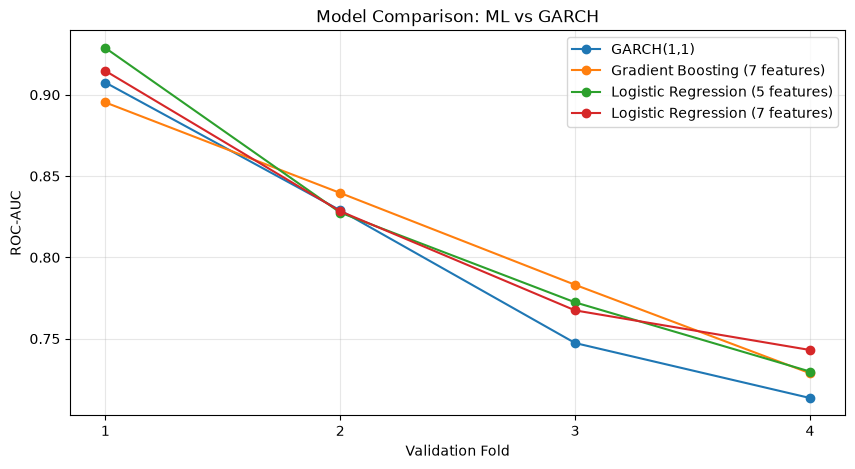

In [97]:
plt.figure(figsize=(10, 5))

for model_name, group in comparison_auc.groupby("Model"):
    plt.plot(
        group["Fold"],
        group["ROC-AUC"],
        marker="o",
        label=model_name
    )

plt.xlabel("Validation Fold")
plt.ylabel("ROC-AUC")
plt.title("Model Comparison: ML vs GARCH")
plt.xticks([1, 2, 3, 4])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Combined advanced-model comparison

| Approach | Mean ROC-AUC | Fold standard deviation |
|---|---:|---:|
| Logistic regression, five features | 0.815 | 0.086 |
| Logistic regression, seven features | 0.813 | 0.076 |
| Gradient boosting, seven features | 0.812 | 0.072 |
| GARCH(1,1) | 0.799 | 0.087 |

The earlier tuned random forest achieved **0.8094** mean ROC-AUC; it is not included in this particular combined table. Five-feature logistic regression remains a reasonable selection because of its competitive development results and simpler specification.

The model differences are modest relative to fold variation. No significance test or independent model-selection assessment is implemented, and repeated use of these same folds can make selected results optimistic.

## 19. Final fit and later-period evaluation

The selected procedure is unweighted, scaled logistic regression using the original five features and a probability cutoff of **0.25**. The final training dataset uses the development portion with its last five rows removed. The later evaluation dataset uses the original 830 test forecast dates.

The high-volatility label cutoff is recalculated from final training targets and then applied to both portions. Missing values and date ordering are checked before fitting. This final refit avoids training-label overlap into evaluation, but the evaluation period has already been inspected and partly touched by development target windows. These results therefore remain exploratory.

In [98]:
# Final training dataset, excluding the last five observations
final_train = development_df.iloc[:-5].copy()

# Final evaluation dataset
final_test = sp500.loc[
    test_data.index,
    features_v2 + ["Future_Volatility_5d"]
].copy()

print("Training period:")
print(final_train.index.min(), "to", final_train.index.max())

print("\nEvaluation period:")
print(final_test.index.min(), "to", final_test.index.max())

print("\nTraining observations:", len(final_train))
print("Evaluation observations:", len(final_test))

Training period:
2010-03-31 00:00:00 to 2023-05-24 00:00:00

Evaluation period:
2023-06-02 00:00:00 to 2026-09-23 00:00:00

Training observations: 3311
Evaluation observations: 830


In [99]:
final_vol_threshold = (
    final_train["Future_Volatility_5d"].quantile(0.75)
)

final_train["High_Volatility_Final"] = (
    final_train["Future_Volatility_5d"] > final_vol_threshold
).astype(int)

final_test["High_Volatility_Final"] = (
    final_test["Future_Volatility_5d"] > final_vol_threshold
).astype(int)

print("Final volatility threshold:", final_vol_threshold)

print("\nTraining class distribution:")
print(
    final_train["High_Volatility_Final"]
    .value_counts(normalize=True)
)

print("\nEvaluation class distribution:")
print(
    final_test["High_Volatility_Final"]
    .value_counts(normalize=True)
)

Final volatility threshold: 1.1239353643995877

Training class distribution:
High_Volatility_Final
0    0.749924
1    0.250076
Name: proportion, dtype: float64

Evaluation class distribution:
High_Volatility_Final
0    0.853012
1    0.146988
Name: proportion, dtype: float64


In [100]:
print("Missing training features:")
print(final_train[features_v2].isna().sum())

print("\nMissing evaluation features:")
print(final_test[features_v2].isna().sum())

print("\nMissing target values:")
print(
    final_train["High_Volatility_Final"].isna().sum(),
    final_test["High_Volatility_Final"].isna().sum()
)

print("\nTraining ends before evaluation starts:")
print(final_train.index.max() < final_test.index.min())

print(
    "Missing continuous targets:",
    final_train["Future_Volatility_5d"].isna().sum(),
    final_test["Future_Volatility_5d"].isna().sum()
)


Missing training features:
Price
Volatility_5d       0
Volatility_20d      0
Volatility_60d      0
Return_5d           0
Volatility_Ratio    0
dtype: int64

Missing evaluation features:
Price
Volatility_5d       0
Volatility_20d      0
Volatility_60d      0
Return_5d           0
Volatility_Ratio    0
dtype: int64

Missing target values:
0 0

Training ends before evaluation starts:
True
Missing continuous targets: 0 0


### Final training and evaluation setup

| Portion | Forecast dates | Observations | High-volatility share |
|---|---|---:|---:|
| Final training | 31 Mar 2010–24 May 2023 | 3,311 | 25.01% |
| Later evaluation | 2 Jun 2023–23 Sep 2026 | 830 | 14.70% |

The final training-derived volatility cutoff is **1.123935**, the same value used in the initial 80/20 experiment. The final model differs from that initial model because it uses five features rather than three and a 0.25 alert cutoff rather than the default rule.

The checks report no missing selected features or targets and confirm that training forecast dates precede evaluation forecast dates. The code explicitly removes five training rows; a date-order check alone would not establish separation of forward target windows.

The next cells fit the final pipeline, generate probabilities and alerts, report classification metrics and the always-low baseline, and plot the ROC curve.

In [101]:
final_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

X_train = final_train[features_v2]
y_train = final_train["High_Volatility_Final"]

X_test = final_test[features_v2]
y_test = final_test["High_Volatility_Final"]

In [102]:
final_model.fit(X_train, y_train)

print("Final model trained successfully.")
print("Training observations:", len(X_train))
print("Features:", list(X_train.columns))

Final model trained successfully.
Training observations: 3311
Features: ['Volatility_5d', 'Volatility_20d', 'Volatility_60d', 'Return_5d', 'Volatility_Ratio']


In [103]:
final_probabilities = final_model.predict_proba(X_test)[:, 1]

final_predictions = (
    final_probabilities >= 0.25
).astype(int)

final_results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": final_predictions,
    "Probability": final_probabilities
}, index=X_test.index)

final_results.head(10)

,Actual,Predicted,Probability
Date,,,
2023-06-02,0,0,0.089110
2023-06-05,0,0,0.109363
2023-06-06,0,0,0.102087
2023-06-07,0,0,0.092469
2023-06-08,0,0,0.098004
2023-06-09,0,0,0.106924
2023-06-12,0,0,0.088964
2023-06-13,0,0,0.081494
2023-06-14,0,0,0.062358


In [104]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

final_metrics = {
    "Accuracy": accuracy_score(y_test, final_predictions),
    "Precision": precision_score(
        y_test, final_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, final_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test, final_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, final_probabilities
    )
}

print("Final Model Performance")
print("-----------------------")

for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

Final Model Performance
-----------------------
Accuracy: 0.8133
Precision: 0.3962
Recall: 0.5164
F1: 0.4484
ROC-AUC: 0.7112

Confusion Matrix:
[[612  96]
 [ 59  63]]


In [105]:
baseline_predictions = np.zeros(len(y_test), dtype=int)

print("Baseline accuracy:",
      accuracy_score(y_test, baseline_predictions))

print("Final model accuracy:",
      accuracy_score(y_test, final_predictions))

print("Baseline F1:",
      f1_score(y_test, baseline_predictions, zero_division=0))

print("Final model F1:",
      f1_score(y_test, final_predictions, zero_division=0))

Baseline accuracy: 0.8530120481927711
Final model accuracy: 0.8132530120481928
Baseline F1: 0.0
Final model F1: 0.4483985765124555


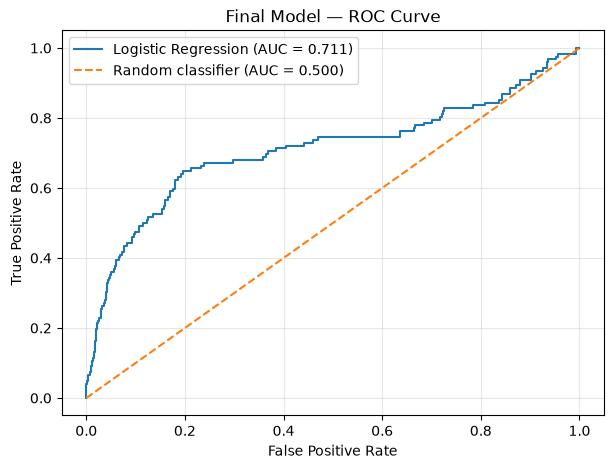

In [106]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    final_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {final_metrics['ROC-AUC']:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier (AUC = 0.500)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Model — ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Final later-period results

| Metric | Saved result |
|---|---:|
| Accuracy | 0.8133 |
| Precision | 0.3962 |
| Recall | 0.5164 |
| F1 | 0.4484 |
| ROC-AUC | 0.7112 |

The confusion matrix is `[[612, 96], [59, 63]]`. The model detects **63 of 122 high-volatility observations**, misses **59**, and generates **96 false-positive alerts**. Of 159 total alerts, 63 are correct. These are daily forecast observations with overlapping targets, not 122 independent episodes.

The always-low baseline has higher accuracy, **0.8530**, but recall and F1 of zero for the high-volatility class. The model's lower accuracy and nonzero detection rate illustrate an alerting trade-off; practical value would depend on the costs of missed events and false alerts, which are not modelled here.

ROC-AUC of **0.7112** indicates moderate ranking discrimination in this saved evaluation. It is below the development mean of approximately **0.815**, although that mean combines different periods, training sizes and fold-specific label definitions. The gap does not by itself identify the cause of weaker performance.

The results cannot be presented as a clean, untouched holdout estimate because this period was used for the initial modelling and cutoff exploration. Calibration, profitability and live predictive performance have not been established.

## 20. Interpreting the selected model

Interpretation proceeds in three stages: coefficients from the final fitted logistic model, feature correlations in final training data, and permutation importance from a **separate model fitted on the last development fold's training portion**.

The following cells extract and rank coefficients, install the plotting dependency, and display the feature correlation matrix.

In [107]:
# Extract the fitted logistic regression model
logistic_model = final_model.named_steps["logisticregression"]

# Extract coefficients
coefficients = logistic_model.coef_[0]

# Create a dataframe
coefficient_df = pd.DataFrame({
    "Feature": features_v2,
    "Coefficient": coefficients
})

# Sort by absolute coefficient magnitude
coefficient_df["Absolute_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

coefficient_df

,Feature,Coefficient,Absolute_Coefficient
1,Volatility_20d,1.052463,1.052463
3,Return_5d,-0.595548,0.595548
2,Volatility_60d,0.441525,0.441525
4,Volatility_Ratio,0.276058,0.276058
0,Volatility_5d,0.003454,0.003454


In [108]:

%pip install seaborn



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


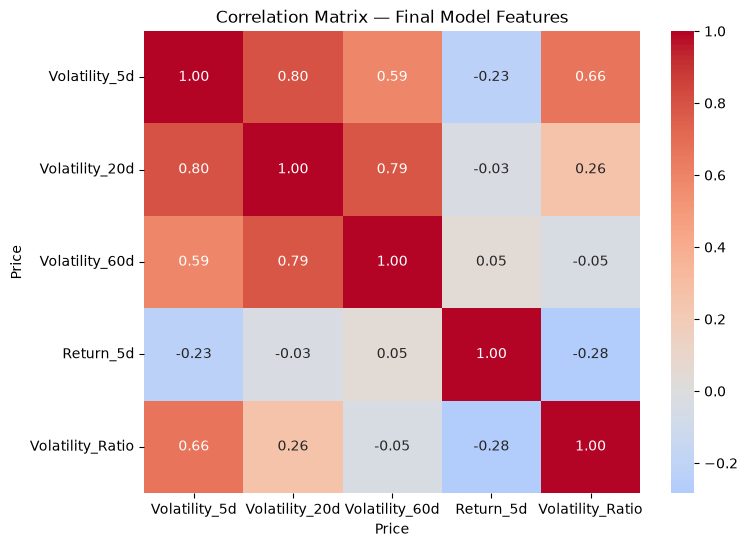

In [109]:
correlation_matrix = final_train[features_v2].corr()

plt.figure(figsize=(8, 6))

import seaborn as sns

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Matrix — Final Model Features")
plt.show()

### Standardised coefficients and feature dependence

| Feature | Final-model coefficient |
|---|---:|
| 20-day volatility | +1.0525 |
| Five-day return | −0.5955 |
| 60-day volatility | +0.4415 |
| Volatility ratio | +0.2761 |
| Five-day volatility | +0.0035 |

Because the pipeline standardises features, a coefficient describes the change in predicted **log-odds** for a one-training-standard-deviation increase in that feature, holding the others fixed. A negative five-day-return coefficient associates lower recent returns with higher predicted odds. Coefficients are not probability-point effects or causal estimates.

The training correlation heatmap reports correlations of approximately **0.80** between five-day and 20-day volatility, **0.79** between 20-day and 60-day volatility, and **0.59** between five-day and 60-day volatility. Correlated predictors share information, complicating interpretation of any one coefficient. The near-zero five-day-volatility coefficient does not establish that recent volatility has no predictive value.

### Permutation importance on the last development fold

The next cells fit a separate five-feature logistic pipeline on the fourth fold's training data, create labels from that fold's training-only cutoff, and measure the change in validation ROC-AUC after shuffling one feature at a time. Each feature is shuffled 20 times with a fixed random seed.

This analysis concerns the fourth-fold model and validation period, not permutation importance of the final refitted model on the later evaluation period.

In [110]:
from sklearn.inspection import permutation_importance

# Retrieve the last chronological validation fold
train_idx, val_idx = list(tscv.split(development_df))[-1]

importance_train = development_df.iloc[train_idx]
importance_val = development_df.iloc[val_idx]

# Define high volatility from training data only
importance_threshold = (
    importance_train["Future_Volatility_5d"].quantile(0.75)
)

y_importance_train = (
    importance_train["Future_Volatility_5d"]
    > importance_threshold
).astype(int)

y_importance_val = (
    importance_val["Future_Volatility_5d"]
    > importance_threshold
).astype(int)

# Train a separate model for interpretation
importance_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

importance_model.fit(
    importance_train[features_v2],
    y_importance_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Volatility_5d','Volatility_20d','Volatility_60d','Return_5d', 'Volatility_Ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [111]:
importance_results = permutation_importance(
    importance_model,
    importance_val[features_v2],
    y_importance_val,
    scoring="roc_auc",
    n_repeats=20,
    random_state=42
)

importance_df = pd.DataFrame({
    "Feature": features_v2,
    "Importance_Mean": importance_results.importances_mean,
    "Importance_Std": importance_results.importances_std
})

importance_df = importance_df.sort_values(
    "Importance_Mean",
    ascending=False
)

importance_df.round(4)

,Feature,Importance_Mean,Importance_Std
1,Volatility_20d,0.1059,0.0174
3,Return_5d,0.0742,0.0129
2,Volatility_60d,0.0347,0.0092
4,Volatility_Ratio,0.0088,0.0051
0,Volatility_5d,0.0039,0.0029


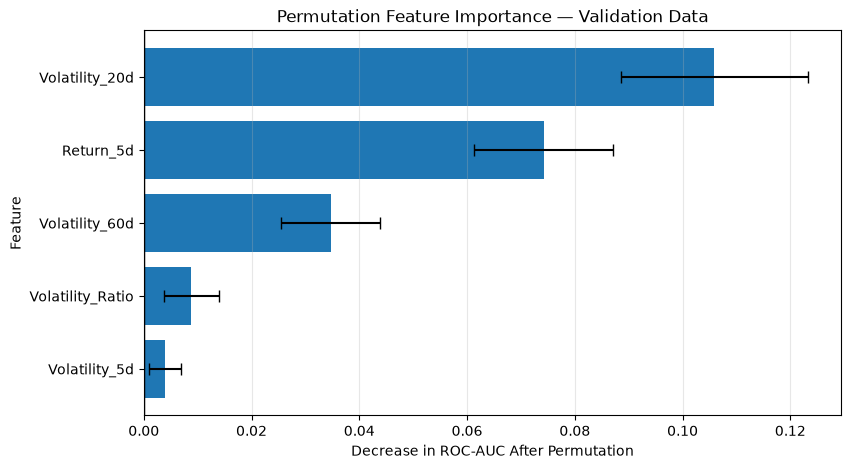

In [112]:
plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance_Mean"],
    xerr=importance_df["Importance_Std"],
    capsize=4
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Decrease in ROC-AUC After Permutation")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance — Validation Data")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.show()

### Permutation-importance findings

| Feature | Mean ROC-AUC decrease | Standard deviation across shuffles |
|---|---:|---:|
| 20-day volatility | 0.1059 | 0.0174 |
| Five-day return | 0.0742 | 0.0129 |
| 60-day volatility | 0.0347 | 0.0092 |
| Volatility ratio | 0.0088 | 0.0051 |
| Five-day volatility | 0.0039 | 0.0029 |

Twenty-day volatility and five-day returns make the largest contributions to discrimination under this particular permutation experiment. Correlated features can substitute for each other, so low individual importance may reflect redundancy. Independently shuffling a time-series feature also disrupts temporal structure and relationships between predictors, making the scores a diagnostic rather than a realistic market intervention.

The error bars describe variability across the 20 random shuffles. They are not confidence intervals for future performance, nor do they measure variation across market regimes. This validation fold has been reused during development, and its final target windows extend into the later evaluation period as noted above.

## 21. Conclusions and limitations

### What the implemented experiments show

Historical volatility and recent returns provide predictive ranking information in the examined sample, but the ability to issue accurate high-volatility alerts varies across periods. The five-feature logistic procedure achieves mean development ROC-AUC of approximately **0.815**, followed by **0.711** on the previously inspected later period.

At the retained 0.25 cutoff, later-period recall is **51.6%** and precision is **39.6%**. The model identifies observations that an always-low rule misses, while producing substantial false alerts and lower accuracy than that rule. The tested increases in model complexity do not consistently improve development results. This is evidence about the implemented experiments, not a claim that logistic regression is generally superior to more complex methods.

### Methodological limits

- **Test reuse:** the later evaluation period was inspected in the initial model and probability-cutoff experiments. It is not an untouched holdout.
- **Repeated development selection:** feature choices, forest tuning, model comparisons and cutoff selection reuse the same development periods. The selected validation scores can be optimistic; nested evaluation is not implemented.
- **Development target spillover:** the last five development targets use returns from the later evaluation period. Final fitting purges those rows, but earlier selection and last-fold interpretation have already used them.
- **Dependent observations:** overlapping forward targets and rolling features create temporal dependence. Daily positive counts are not counts of independent events. Reported fold standard deviations and permutation error bars are not inferential confidence intervals.
- **Changing labels and prevalence:** training-derived volatility cutoffs differ between experiments and folds. Comparisons across periods involve changes in both market conditions and the operational high-volatility definition.
- **Information timing:** features require the current close. Same-day pre-close predictions, execution feasibility and publication delays have not been tested.
- **Interpretation limits:** correlated predictors complicate individual attribution. Coefficients and permutation scores describe associations, not causes; permutation importance is measured on one reused fold with a separate fitted model.
- **Benchmark scope:** GARCH provides a conditional-volatility ranking score rather than a calibrated high-volatility probability or an exact forecast of the five-return sample standard deviation. No forecast-loss benchmark is reported.
- **Data and reproducibility:** only one provider's S&P 500 history is used. Downloaded prices and installed package versions may change; the notebook does not establish an immutable source-data snapshot. No external indicators or volume predictors are used in the implemented models.
- **Practical validation:** probability calibration, trading returns, transaction costs, economic alert costs and prospective performance are not evaluated.

### Next research steps

Freeze the feature definitions, label rule, model specification and alert cutoff before evaluating a new period that has not informed development. Separate development from that period by target end dates, not only by forecast dates. Further work could use nested chronological selection, dependence-aware uncertainty estimates, calibration checks, and operational alert-cost evaluation.

The present model is best understood as an exploratory volatility-warning prototype. Its saved results support further research, while leaving independent generalisation and practical usefulness unresolved.

## 22. Benchmark check and FX extension
Two questions remained: does the model beat a simple rule with no fitting (flag high volatility when the last 20 days were volatile), and does the result hold outside equities? The next cell defines the functions. Test-period differences are assessed with a moving-block bootstrap, which keeps the overlap between neighbouring daily labels.

In [113]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss, precision_score, recall_score
import numpy as np, pandas as pd

FEATS = ["Vol_5d", "Vol_20d", "Vol_60d", "Return_5d", "Vol_Ratio"]

def build(close):
    d = pd.DataFrame({"Close": close})
    d["ret"] = d["Close"].pct_change() * 100
    for w in (5, 20, 60):
        d[f"Vol_{w}d"] = d["ret"].rolling(w).std()
    d["Return_5d"] = d["Close"].pct_change(5) * 100
    d["Vol_Ratio"] = d["Vol_5d"] / d["Vol_60d"]
    d["Future_Vol"] = d["ret"].rolling(5).std().shift(-5)
    return d.dropna(subset=FEATS + ["Future_Vol"])

def models():
    return {
        "Rule: 20d vol only": None,
        "Logistic, 3 vol features": (["Vol_5d", "Vol_20d", "Vol_60d"],
            make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
        "Logistic, 5 features": (FEATS,
            make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
        "Gradient boosting": (FEATS,
            GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=0.05, random_state=0)),
    }

def scores(tr, te, thr):
    ytr, yte = (tr.Future_Vol > thr).astype(int), (te.Future_Vol > thr).astype(int)
    out = {}
    for name, spec in models().items():
        if spec is None:
            out[name] = te["Vol_20d"].values
        else:
            cols, m = spec
            out[name] = m.fit(tr[cols], ytr).predict_proba(te[cols])[:, 1]
    return out, yte.values

def block_bootstrap_auc_diff(y, a, b, block=20, n=1000, seed=0):
    rng, N = np.random.default_rng(seed), len(y)
    starts, diffs = np.arange(N - block), []
    for _ in range(n):
        idx = np.concatenate([np.arange(s, s + block) for s in rng.choice(starts, N // block + 1)])[:N]
        if y[idx].min() == y[idx].max():
            continue
        diffs.append(roc_auc_score(y[idx], a[idx]) - roc_auc_score(y[idx], b[idx]))
    return np.percentile(diffs, [2.5, 97.5])

def run(close, label, gap=5, folds=4, fold_size=400, test_frac=0.2):
    d = build(close)
    cut = int(len(d) * (1 - test_frac))
    dev, test = d.iloc[:cut - gap], d.iloc[cut:]
    rows = []
    for k, (a, b) in enumerate(TimeSeriesSplit(folds, test_size=fold_size, gap=gap).split(dev), 1):
        tr, va = dev.iloc[a], dev.iloc[b]
        s, y = scores(tr, va, tr.Future_Vol.quantile(0.75))
        rows += [dict(Fold=k, Model=m, AUC=roc_auc_score(y, v)) for m, v in s.items()]
    wf = pd.DataFrame(rows).pivot(index="Model", columns="Fold", values="AUC")
    wf["Mean"] = wf.mean(axis=1)

    thr = dev.Future_Vol.quantile(0.75)
    s, y = scores(dev, test, thr)
    ref = "Rule: 20d vol only"
    res = []
    for m, v in s.items():
        lo, hi = (np.nan, np.nan) if m == ref else block_bootstrap_auc_diff(y, v, s[ref])
        res.append(dict(Model=m, Test_AUC=roc_auc_score(y, v), Diff_vs_rule_lo=lo, Diff_vs_rule_hi=hi))
    test_tbl = pd.DataFrame(res).set_index("Model")

    p = s["Logistic, 5 features"]
    cal = pd.DataFrame({"p": p, "y": y})
    cal["bin"] = pd.qcut(cal.p, 5, duplicates="drop")
    reliability = cal.groupby("bin", observed=True).agg(mean_pred=("p", "mean"), observed=("y", "mean"))
    brier = brier_score_loss(y, p)
    cost = pd.DataFrame([dict(cutoff=c, alerts=int((p >= c).sum()), hits=int(((p >= c) & (y == 1)).sum()),
                              precision=precision_score(y, p >= c, zero_division=0),
                              recall=recall_score(y, p >= c, zero_division=0)) for c in (.15, .25, .35, .5)])
    print(f"\n===== {label} =====\nWalk-forward AUC\n{wf.round(3)}\n\nTest AUC and 95% block-bootstrap CI of difference vs rule\n{test_tbl.round(3)}")
    print(f"\nBrier (5-feat logistic): {brier:.3f} | base rate {y.mean():.3f}\n{reliability.round(3)}\n\n{cost.round(3)}")

In [114]:
px = yf.download("^GSPC", start="2010-01-01", end="2026-10-01", auto_adjust=True, progress=False)["Close"].squeeze().dropna()
run(px, "S&P 500")


===== S&P 500 =====
Walk-forward AUC
Fold                          1      2      3      4   Mean
Model                                                      
Gradient boosting         0.847  0.825  0.798  0.728  0.799
Logistic, 3 vol features  0.912  0.781  0.765  0.705  0.791
Logistic, 5 features      0.927  0.824  0.778  0.732  0.815
Rule: 20d vol only        0.887  0.765  0.744  0.698  0.773

Test AUC and 95% block-bootstrap CI of difference vs rule
                          Test_AUC  Diff_vs_rule_lo  Diff_vs_rule_hi
Model                                                               
Rule: 20d vol only           0.611              NaN              NaN
Logistic, 3 vol features     0.628           -0.019            0.054
Logistic, 5 features         0.711            0.038            0.169
Gradient boosting            0.721            0.040            0.189

Brier (5-feat logistic): 0.112 | base rate 0.147
                  mean_pred  observed
bin                                  
(0.

### S&P 500 benchmark results
The five-feature logistic regression beats the 20-day rule in every walk-forward fold (mean AUC 0.815 vs 0.773) and on the later test period (0.711 vs 0.611). The 95% block-bootstrap interval for the test difference is +0.038 to +0.169, which excludes zero. The three-feature version does not beat the rule (interval -0.019 to +0.054), so the gain comes from the added 5-day return and volatility ratio. Gradient boosting is similar on test (0.721) but lower on walk-forward (0.799), so it is not shown to be better than logistic regression.

Calibration is imperfect. The test period had fewer high-volatility days (14.7%) than training (25%), so the model overstates risk in the middle of the probability range. Treat the scores as a ranking, not literal probabilities. At the 0.25 cutoff the model flags 159 days and catches 63 of the 122 high-volatility days (recall 0.52, precision 0.40).

In [115]:
for tkr, label in [("GBPUSD=X", "GBP/USD"), ("EURGBP=X", "EUR/GBP"), ("USDJPY=X", "USD/JPY")]:
    px = yf.download(tkr, start="2010-01-01", end="2026-10-01", auto_adjust=True, progress=False)["Close"].squeeze().dropna()
    run(px, label)


===== GBP/USD =====
Walk-forward AUC
Fold                          1      2      3      4   Mean
Model                                                      
Gradient boosting         0.474  0.631  0.546  0.732  0.596
Logistic, 3 vol features  0.409  0.606  0.633  0.749  0.599
Logistic, 5 features      0.410  0.608  0.632  0.755  0.601
Rule: 20d vol only        0.424  0.609  0.569  0.775  0.594

Test AUC and 95% block-bootstrap CI of difference vs rule
                          Test_AUC  Diff_vs_rule_lo  Diff_vs_rule_hi
Model                                                               
Rule: 20d vol only           0.571              NaN              NaN
Logistic, 3 vol features     0.585           -0.025            0.057
Logistic, 5 features         0.580           -0.031            0.052
Gradient boosting            0.542           -0.091            0.059

Brier (5-feat logistic): 0.111 | base rate 0.126
                 mean_pred  observed
bin                                 
(0.09

### FX results
No model clearly beats the 20-day rule on any currency pair, because every bootstrap interval includes zero. Test AUC is weak for GBP/USD (about 0.58) and USD/JPY (about 0.62). USD/JPY models look better in walk-forward (0.695 to 0.710 vs 0.661) but not on the test period. EUR/GBP's test period contains only about 1.5% high-volatility days (a dozen or so), so its AUC and intervals are not informative.

The 0.25 cutoff was chosen on S&P data and does not transfer: on GBP/USD and EUR/GBP it produces almost no alerts, so those alert tables should be ignored. The takeaway is that the equity signal does not carry over to these currency pairs at a 5-day horizon, and a label threshold fixed on training data breaks when volatility regimes shift. These results do not test any specific business application.

## 23. Updated conclusion
Taken together with Section 21: on the S&P 500, the five-feature logistic regression beat a simple 20-day-volatility rule in every walk-forward fold and on the later period, and the more complex models (gradient boosting, GARCH) did not improve on it. The same approach did not beat the rule on GBP/USD, EUR/GBP or USD/JPY, so the signal does not appear to be general. The S&P 500 result remains exploratory for the reasons listed in Section 21: a reused test period, overlapping labels, and a single label definition and horizon.